# Project P05 - Text-to-SQL Analyst

**Team:**   
    G. Greeshma - S20230030380     
    P. Meghana  - S20230030400        
    D. LeenaShri Reddy - S20230030376      
    Uma Charitha - S20230030388       
    G. Vyshnavi - S20230030378       
    S. Balaji Sai Surya - S20230010211       


## 1. Problem Statement

- **Problem:** Convert natural-language questions into safe, executable SQLite queries over a supplied database context.
- **Research question:** Do retrieval, structured generation, LoRA fine-tuning, and an execution-guided repair loop improve execution accuracy over zero-shot generation?
- **Success metric:** Execution accuracy, measured by comparing the result rows of generated SQL with the gold SQL on the same fixed validation and test IDs.

This notebook consolidates the implemented Parts 1-5. Part 1 cleans the dataset and creates reproducible splits; Part 2 builds and evaluates retrieval-augmented generation; Part 3 adds a LangGraph agent and repair loop; Part 4 adds LoRA fine-tuning; and Part 5 performs the final comparison and error analysis.

In [ ]:
# Install the complete project dependency set into the active notebook kernel when needed.
import importlib.util
import subprocess
import sys

_required = {
    "datasets": "datasets",
    "transformers": "transformers",
    "accelerate": "accelerate",
    "peft": "peft",
    "trl": "trl",
    "torch": "torch",
    "faiss": "faiss-cpu",
    "sentence_transformers": "sentence-transformers",
    "rank_bm25": "rank-bm25",
    "langgraph": "langgraph",
    "langchain_core": "langchain-core",
    "langchain_community": "langchain-community",
    "langchain_text_splitters": "langchain-text-splitters",
    "langchain_huggingface": "langchain-huggingface",
    "langchain_ollama": "langchain-ollama",
    "mcp": "mcp",
    "outlines": "outlines",
    "pydantic": "pydantic",
    "matplotlib": "matplotlib",
    "pandas": "pandas",
    "numpy": "numpy",
    "tqdm": "tqdm",
}
_missing = [package for module, package in _required.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *_missing])
    print(f"Installed: {', '.join(_missing)}")
else:
    print("All project dependencies are already installed.")

Retrieval and agent dependencies already installed.


In [ ]:
import sys, types, linecache

def embed_module(name, source):
    filename = f"<embedded {name}.py>"
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    mod = types.ModuleType(name)
    mod.__file__ = filename
    sys.modules[name] = mod
    exec(compile(source, filename, "exec"), mod.__dict__)
    return mod

CONFIG_SOURCE = r'''
import random
import numpy as np

SEED = 42
QUICK_RUN = False      # True = small sample for fast runs
TRAIN = False         # False = load saved LoRA adapter

CONFIG = {
    "dataset": "gretelai/synthetic_text_to_sql",
    "llm": "Qwen/Qwen2.5-Coder-1.5B-Instruct",     # agent / few-shot
    "lora_base": "Qwen/Qwen2.5-0.5B-Instruct",     # fine-tuning
    "embedder": "sentence-transformers/all-MiniLM-L6-v2",
    "top_k": 3,
    "test_size": 200,
    "quick_test_size": 20,
    "max_repairs": 3,
    "lora_train_size": 1000,
    "test_ids_path": "test_ids.json",
    "adapter_path": "lora_adapter/",
}

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except ImportError:
        pass
'''
embed_module("config", CONFIG_SOURCE)
print("module 'config' ready")

In [ ]:
DATA_SOURCE = r'''
import re, sys, json, math, time, random, sqlite3
from pathlib import Path
from typing import Any, Dict, List, Optional, Set, Tuple
from collections import Counter, defaultdict
from itertools import zip_longest

import datasets

try:
    from config import CONFIG, SEED, QUICK_RUN
except ImportError:
    SEED = 42
    QUICK_RUN = True
    CONFIG = {
        "dataset": "gretelai/synthetic_text_to_sql",
        "test_size": 200,
        "quick_test_size": 20,
        "val_size": 200,
        "test_ids_path": "test_ids.json",
        "val_ids_path": "val_ids.json",
        "train_ids_path": "train_ids.json",
        "excluded_ids_path": "excluded_ids.json",
        "filter_report_path": "filter_report.json",
    }

_DATASET_CACHE: Optional[datasets.DatasetDict] = None


_WRITE_RE = re.compile(
    r"^\s*(UPDATE|DELETE|INSERT|DROP|ALTER|CREATE|REPLACE|TRUNCATE|MERGE)\b",
    re.IGNORECASE,
)

def load_data() -> datasets.DatasetDict:
    """Loads and memory-caches the configured HuggingFace dataset."""
    global _DATASET_CACHE
    if _DATASET_CACHE is not None:
        return _DATASET_CACHE

    name = CONFIG.get("dataset", "gretelai/synthetic_text_to_sql")
    try:
        ds = datasets.load_dataset(name)
    except Exception as e:
        raise RuntimeError(
            f"Cannot load '{name}': {e}\n"
            "Check internet access, disk space, or set HF_TOKEN."
        ) from e

    if not {"train", "test"}.issubset(ds.keys()):
        raise RuntimeError(f"Expected 'train' and 'test' splits, got: {list(ds.keys())}")

    required = {"id", "domain", "sql_complexity", "sql_prompt", "sql_context", "sql"}
    for split in ("train", "test"):
        missing = required - set(ds[split].column_names)
        if missing:
            raise RuntimeError(f"Split '{split}' missing columns: {missing}")

    _DATASET_CACHE = ds
    return _DATASET_CACHE

def run_sql(
    sql_context: Optional[str],
    sql: str,
    timeout: float = 5.0,
) -> Tuple[Optional[List[Tuple]], Optional[str]]:
    """
    Runs sql in a fresh in-memory SQLite database seeded from sql_context.

    Safety layers:
      - PRAGMA query_only blocks writes at the SQLite level.
      - set_authorizer denies any non-read action (INSERT, UPDATE, DELETE, DROP, ...).
      - Progress handler kills queries that exceed timeout seconds.
      - cursor.execute() rejects multiple statements in one call.

    Returns (rows, None) on success, (None, error_message) on any failure.
    """
    if not sql or not isinstance(sql, str) or not sql.strip():
        return None, "Empty or invalid SQL string"

    conn = None
    timed_out = False
    try:
        conn = sqlite3.connect(":memory:")

        if sql_context and sql_context.strip():
            try:
                conn.executescript(sql_context)
            except Exception as e:
                return None, f"Context setup error: {e}"

        try:
            conn.execute("PRAGMA query_only = ON;")
        except Exception as e:
            return None, f"Could not enable read-only mode: {e}"

        _allowed = {
            sqlite3.SQLITE_SELECT,
            sqlite3.SQLITE_READ,
            sqlite3.SQLITE_FUNCTION,
            sqlite3.SQLITE_RECURSIVE,
        }

        def _auth(action, *_):
            return sqlite3.SQLITE_OK if action in _allowed else sqlite3.SQLITE_DENY

        conn.set_authorizer(_auth)

        start = time.perf_counter()

        def _progress():
            nonlocal timed_out
            if time.perf_counter() - start > timeout:
                timed_out = True
                return 1
            return 0

        if timeout > 0:
            conn.set_progress_handler(_progress, 1000)

        cur = conn.cursor()
        cur.execute(sql.strip())
        return list(cur.fetchall()), None

    except sqlite3.OperationalError as e:
        if timed_out or "interrupted" in str(e).lower():
            return None, f"Query timed out after {timeout}s"
        return None, f"SQL operational error: {e}"
    except sqlite3.ProgrammingError as e:
        if "one statement" in str(e).lower():
            return None, f"Multiple statements not allowed: {e}"
        return None, f"SQL programming error: {e}"
    except sqlite3.DatabaseError as e:
        if "not authorized" in str(e).lower():
            return None, f"Write/DDL operation blocked: {e}"
        return None, f"SQL database error: {e}"
    except Exception as e:
        return None, f"Unexpected error: {e}"
    finally:
        if conn:
            try:
                conn.set_progress_handler(None, 0)
                conn.set_authorizer(None)
                conn.close()
            except Exception:
                pass
                
def _norm_cell(val: Any) -> Any:
    if val is None:
        return None
    if isinstance(val, bool):
        return val
    if isinstance(val, (int, float)):
        return "__NAN__" if (isinstance(val, float) and math.isnan(val)) else round(float(val), 4)
    if isinstance(val, str):
        return val.strip()
    return val


def _norm_row(row: Any) -> Tuple:
    if isinstance(row, (list, tuple)):
        return tuple(_norm_cell(c) for c in row)
    return (_norm_cell(row),)


def same_result(pred_rows: Any, gold_rows: Any) -> bool:
    """
    Order-insensitive multiset comparison of SQL result rows.
    Handles numeric tolerance (1 == 1.0), NULL, NaN, and string whitespace.
    Returns False if either argument is None (signals an execution error).
    """
    if pred_rows is None or gold_rows is None:
        return False
    if not isinstance(pred_rows, list) or not isinstance(gold_rows, list):
        return False
    if len(pred_rows) != len(gold_rows):
        return False
    if not pred_rows:
        return True
    try:
        return Counter(_norm_row(r) for r in pred_rows) == Counter(_norm_row(r) for r in gold_rows)
    except Exception:
        return False

def check_example(row: Dict) -> Tuple[bool, Optional[str]]:
    """
    Automated quality gate for one dataset row.
    Returns (True, None) if clean, or (False, reason) if it should be removed.

    Checks applied in order:
      1. SQL must start with SELECT or WITH - no writes or DDL allowed.
      2. SQL must execute without error against sql_context.
      3. Gold result must not be empty or trivially matchable (single zero or None).
    """
    sql = (row.get("sql") or "").strip()
    ctx = row.get("sql_context") or ""

    if _WRITE_RE.match(sql):
        op = sql.split()[0].upper() if sql.split() else "?"
        return False, f"Non-read operation - query starts with {op}"

    if not re.match(r"^\s*(SELECT|WITH)\b", sql, re.IGNORECASE):
        return False, f"Does not start with SELECT or WITH: '{sql[:60]}'"

    rows, err = run_sql(ctx, sql)
    if err is not None:
        return False, f"SQL execution failed: {err}"

    if not rows:
        return False, "Gold query returns empty result ([])"

    if len(rows) == 1 and len(rows[0]) == 1:
        val = rows[0][0]
        if val is None:
            return False, f"Gold query returns trivial result: {rows}"
        if isinstance(val, (int, float)) and not isinstance(val, bool) and val == 0:
            return False, f"Gold query returns trivial result: {rows}"

    return True, None


def load_excluded_ids(path: Path) -> Set[int]:
    """Returns the set of manually flagged IDs from excluded_ids.json."""
    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        ids: Set[int] = set()
        for key in ("test_exclusions", "train_exclusions"):
            for entry in data.get(key, []):
                ids.add(int(entry["id"]))
        return ids
    except FileNotFoundError:
        return set()
    except Exception as e:
        print(f"[Warning] Could not load {path}: {e}", file=sys.stderr)
        return set()


def clean_split(
    ds_split: datasets.Dataset,
    split_name: str,
    excluded_ids: Optional[Set[int]] = None,
    show_progress: bool = True,
) -> Tuple[List[Dict], List[Dict]]:
    """
    Filters ds_split and returns (clean_rows, removal_log).

    Each removal_log entry: { id, split, reason, sql_prompt[:100], sql[:100] }

    Removals are applied in order:
      1. IDs listed in excluded_ids (manual audit flags from excluded_ids.json).
      2. Non-read / DDL operations (UPDATE, DELETE, INSERT, DROP, ...).
      3. SQL execution errors (syntax, missing table, unsupported dialect, ...).
      4. Empty gold result ([]).
      5. Trivial single-cell result ([(0,)] / [(None,)]) - matchable by chance.
    """
    excluded_ids = excluded_ids or set()
    clean: List[Dict] = []
    log: List[Dict] = []
    total = len(ds_split)

    for i, row in enumerate(ds_split):
        rid = row.get("id")

        if rid in excluded_ids:
            log.append({
                "id": rid, "split": split_name,
                "reason": "Manual exclusion (see excluded_ids.json)",
                "sql_prompt": (row.get("sql_prompt") or "")[:100],
                "sql": (row.get("sql") or "")[:100],
            })
        else:
            valid, reason = check_example(row)
            if valid:
                clean.append(dict(row))
            else:
                log.append({
                    "id": rid, "split": split_name,
                    "reason": reason,
                    "sql_prompt": (row.get("sql_prompt") or "")[:100],
                    "sql": (row.get("sql") or "")[:100],
                })

        if show_progress and (i + 1) % 1000 == 0:
            print(
                f"\r  {split_name}: {i+1:,}/{total:,} | "
                f"clean: {len(clean):,} | removed: {len(log):,}   ",
                end="", flush=True,
            )

    if show_progress:
        print(
            f"\r  {split_name}: {total:,}/{total:,} | "
            f"clean: {len(clean):,} | removed: {len(log):,}"
        )

    return clean, log


def save_json_list(path: Path, ids: List[int]) -> None:
    """Saves a list of integer IDs to a JSON file."""
    try:
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", encoding="utf-8") as f:
            json.dump(ids, f, indent=2)
    except Exception as e:
        print(f"[Warning] Could not write {path}: {e}", file=sys.stderr)


def _load_json_list(path: Path) -> List[int]:
    try:
        with open(path, "r", encoding="utf-8") as f:
            raw = json.load(f)
        return [int(x) for x in raw] if isinstance(raw, list) else []
    except Exception:
        return []


def stratified_sample(
    rows: List[Dict],
    n: int,
    rng: random.Random,
    key: str = "sql_complexity",
) -> Tuple[List[Dict], List[Dict]]:
    """
    Samples exactly n rows from rows, proportional to each value of key.

    The sampled list is interleaved across groups so the first K items
    span all complexity levels - useful for the QUICK_RUN subset.
    Returns (sampled, remainder).
    """
    if n >= len(rows):
        return rows.copy(), []

    groups: Dict[str, List[Dict]] = defaultdict(list)
    for row in rows:
        groups[row.get(key, "unknown")].append(row)

    total = len(rows)
    alloc: Dict[str, int] = {k: max(1, round(n * len(g) / total)) for k, g in groups.items()}

    # Adjust total allocation to exactly n
    diff = n - sum(alloc.values())
    for k in sorted(groups.keys(), key=lambda k: len(groups[k]), reverse=True):
        if diff == 0:
            break
        if diff > 0:
            alloc[k] = min(alloc[k] + 1, len(groups[k]))
            diff -= 1
        elif diff < 0 and alloc[k] > 1:
            alloc[k] -= 1
            diff += 1

    per_group_sampled: List[List[Dict]] = []
    remainder: List[Dict] = []
    for k, g in groups.items():
        shuffled = g.copy()
        rng.shuffle(shuffled)
        per_group_sampled.append(shuffled[: alloc[k]])
        remainder.extend(shuffled[alloc[k]:])

    sampled = [
        item
        for items in zip_longest(*per_group_sampled)
        for item in items
        if item is not None
    ]
    return sampled, remainder

def get_splits(
    seed: int = SEED,
    quick_run: Optional[bool] = None,
    save_ids: bool = True,
) -> Tuple[datasets.Dataset, datasets.Dataset, datasets.Dataset]:
    """
    Returns (train_ds, val_ds, test_ds) using a clean-first pipeline.

    Pipeline:
      1. If all three ID files exist, load them (fast path).
         Otherwise, run full cleaning on both official splits and save IDs.
      2. test_ds  : 200 stratified clean examples from the official test split.
                    First 20 IDs are the QUICK_RUN subset.
                    QUICK_RUN=True returns only those 20.
      3. val_ds   : 200 stratified clean examples from the remaining test pool,
                    disjoint from test. Used for prompt / hyperparameter selection.
      4. train_ds : All clean examples from the official train split (~52k).
                    Used for RAG indexing and fine-tuning.
    """
    ds = load_data()
    if quick_run is None:
        quick_run = CONFIG.get("QUICK_RUN", QUICK_RUN)

    test_size  = CONFIG.get("test_size", 200)
    val_size   = CONFIG.get("val_size", 200)
    quick_size = CONFIG.get("quick_test_size", 20)

    test_ids_path  = Path(CONFIG.get("test_ids_path",      "test_ids.json"))
    val_ids_path   = Path(CONFIG.get("val_ids_path",        "val_ids.json"))
    train_ids_path = Path(CONFIG.get("train_ids_path",      "train_ids.json"))
    excluded_path  = Path(CONFIG.get("excluded_ids_path",   "excluded_ids.json"))

    if test_ids_path.exists() and val_ids_path.exists() and train_ids_path.exists():
        test_ids  = _load_json_list(test_ids_path)
        val_ids   = _load_json_list(val_ids_path)
        train_ids = _load_json_list(train_ids_path)
    else:
        excluded = load_excluded_ids(excluded_path)
        rng = random.Random(seed)

        print("Cleaning official test split ...")
        clean_test, _ = clean_split(ds["test"],  "test",  excluded, show_progress=True)
        print("Cleaning official train split ...")
        clean_train, _ = clean_split(ds["train"], "train", excluded, show_progress=True)

        test_rows, rest = stratified_sample(clean_test, test_size, rng)
        val_rows, _ = stratified_sample(rest, val_size, rng)

        test_ids = [r["id"] for r in test_rows]
        val_ids = [r["id"] for r in val_rows]
        train_ids = [r["id"] for r in clean_train]

        if save_ids:
            save_json_list(test_ids_path, test_ids)
            save_json_list(val_ids_path, val_ids)
            save_json_list(train_ids_path, train_ids)
            print(f"Saved: {test_ids_path}, {val_ids_path}, {train_ids_path}")

    def _select(official_split: datasets.Dataset, ids: List[int]) -> datasets.Dataset:
        id2idx = {tid: i for i, tid in enumerate(official_split["id"])}
        indices = [id2idx[tid] for tid in ids if tid in id2idx]
        return official_split.select(indices)

    train_ds = _select(ds["train"], train_ids)
    val_ds   = _select(ds["test"],  val_ids)

    active_ids = test_ids[:quick_size] if quick_run else test_ids
    test_ds    = _select(ds["test"], active_ids)

    return train_ds, val_ds, test_ds
    
def self_test_harness() -> None:
    """
    Four assertions that verify run_sql and same_result behave correctly.
    Raises AssertionError with a descriptive message if any test fails.
    """
    ctx = "CREATE TABLE t (x INT); INSERT INTO t VALUES (1), (2);"

    # 1. Gold vs gold must always match
    rows, err = run_sql(ctx, "SELECT x FROM t;")
    assert err is None,          f"Test 1 failed - unexpected error: {err}"
    assert same_result(rows, rows), "Test 1 failed - gold vs gold should be True"

    # 2. DDL write operations must be blocked
    _, err = run_sql(ctx, "DROP TABLE t;")
    assert err is not None, "Test 2 failed - DROP TABLE should have been blocked"

    # 3. A query referencing a missing table must return an error
    _, err = run_sql(ctx, "SELECT * FROM table_does_not_exist_xyz;")
    assert err is not None, "Test 3 failed - bad table reference should return an error"

    # 4. A runaway query must time out
    infinite = (
        "WITH RECURSIVE r(c) AS (VALUES(0) UNION ALL SELECT c+1 FROM r) "
        "SELECT * FROM r;"
    )
    _, err = run_sql(ctx, infinite, timeout=0.1)
    assert err is not None and "timed out" in err.lower(), (
        f"Test 4 failed - infinite query should time out, got: {err}"
    )

    print("All 4 self-tests passed [OK]")
    
def _categorize_reason(reason: str) -> str:
    r = reason.lower()
    if "manual" in r:           return "manual_exclusion"
    if "non-read" in r or "does not start" in r: return "write_or_non_select"
    if "context setup" in r:    return "context_setup_error"
    if "sql execution failed" in r: return "sql_execution_error"
    if "empty result" in r:     return "empty_result"
    if "trivial" in r:          return "trivial_result"
    return "other"


def generate_filter_report(
    test_log: List[Dict],
    train_log: List[Dict],
    test_ids: List[int],
    val_ids: List[int],
    train_ids: List[int],
    test_raw: int = 5851,
    train_raw: int = 100000,
    manual_audit: Optional[Dict] = None,
) -> Dict:
    """
    Builds and saves filter_report.json. Returns the report dict.
    Called from the notebook after cleaning both splits.
    """
    def _counts(log: List[Dict]) -> Dict[str, int]:
        return dict(Counter(_categorize_reason(e["reason"]) for e in log))

    report = {
        "generated_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
        "test_split": {
            "raw_total":         test_raw,
            "removed_total":     len(test_log),
            "removed_by_reason": _counts(test_log),
            "clean_pool_size":   test_raw - len(test_log),
        },
        "train_split": {
            "raw_total":         train_raw,
            "removed_total":     len(train_log),
            "removed_by_reason": _counts(train_log),
            "clean_total":       len(train_ids),
        },
        "final_splits": {
            "test":             len(test_ids),
            "val":              len(val_ids),
            "train_clean_total": len(train_ids),
            "quick_run_subset": CONFIG.get("quick_test_size", 20),
        },
        "manual_audit": manual_audit or {
            "status": "pending manual review (1 example pre-flagged as reference)",
            "test_sampled":        1,
            "test_flagged":        1,
            "test_flag_rate_pct":  round(1 / 60 * 100, 2),
            "train_sampled":       0,
            "train_flagged":       0,
            "train_flag_rate_pct": 0.0,
            "note": "ID 4323 (test): BRICS query returns all rows, no country filter applied.",
        },
    }

    report_path = Path(CONFIG.get("filter_report_path", "filter_report.json"))
    try:
        with open(report_path, "w", encoding="utf-8") as f:
            json.dump(report, f, indent=2)
        print(f"Filter report saved -> {report_path}")
    except Exception as e:
        print(f"[Warning] Could not save filter report: {e}", file=sys.stderr)

    return report


# -- 9. EDA (text-based) -------------------------------------------------------

def run_eda(sample_count: int = 3) -> None:
    """
    Text-based EDA summary. The notebook provides the corresponding plots.
    """
    print("=" * 70)
    print("  EDA - TEXT-TO-SQL ANALYST")
    print("=" * 70)

    ds = load_data()
    train_ds, val_ds, test_ds = get_splits()

    print(f"\n  Official train split : {len(ds['train']):>8,d} rows")
    print(f"  Official test split  : {len(ds['test']):>8,d} rows")
    print(f"  Clean train_ds       : {len(train_ds):>8,d} rows")
    print(f"  Val set (val_ds)     : {len(val_ds):>8,d} rows")
    print(f"  Test set (test_ds)   : {len(test_ds):>8,d} rows")
    print(f"  QUICK_RUN uses first {CONFIG.get('quick_test_size', 20)} test IDs")

    print(f"\n  {sample_count} representative test examples:")
    print("  " + "-" * 66)
    step = max(1, len(test_ds) // sample_count)
    for i in range(sample_count):
        ex = test_ds[i * step]
        print(f"\n  ID {ex['id']} | {ex['domain']} | {ex['sql_complexity']}")
        print(f"  Prompt : {ex['sql_prompt']}")
        print(f"  SQL    : {ex['sql']}")

    print("\n\n  SQL Complexity Distribution:")
    train_ctr = Counter(train_ds["sql_complexity"])
    val_ctr   = Counter(val_ds["sql_complexity"])
    test_ctr  = Counter(test_ds["sql_complexity"])
    print(f"  {'Complexity':<25} {'Train':>9} {'Val':>6} {'Test':>6}")
    print("  " + "-" * 52)
    for comp, cnt in train_ctr.most_common():
        print(
            f"  {comp:<25} {cnt:>9,d} "
            f"{val_ctr.get(comp, 0):>6,d} {test_ctr.get(comp, 0):>6,d}"
        )

    print("\n  Domain Distribution - Top 10:")
    for rank, (dom, cnt) in enumerate(Counter(train_ds["domain"]).most_common(10), 1):
        print(f"  {rank:>2}. {dom:<35} {cnt:>7,d}")

    print("\n" + "=" * 70)

if __name__ == "__main__":
    self_test_harness()
    run_eda()
'''
embed_module("data", DATA_SOURCE)
print("module 'data' ready")

# Text-to-SQL Analyst: One Integrated Project

Dataset: `gretelai/synthetic_text_to_sql` (100,000 training examples and 5,851 official test examples).

This notebook is the single consolidated implementation. Parts 1-5 are sequential stages of one workflow:

| Part | Integrated stage | Main outputs |
|---|---|---|
| 1 | Data cleaning, SQL safety checks, exploratory analysis, and reproducible train/validation/test splits | Clean data, fixed ID files, filter report, EDA figures |
| 2 | Retrieval-augmented SQL generation with dense, BM25, hybrid, masked, and skeleton retrieval | Retrieval indexes, validation comparison, selected test configuration |
| 3 | LangGraph SQL agent with execution, repair, explanation, and optional majority voting | Agent trace, repair metrics, failure categories |
| 4 | LoRA fine-tuning and direct model evaluation | Saved adapters, fine-tuning metrics, comparison figures |
| 5 | Final evaluation, controlled ablations, error analysis, and missing-run status | Final tables, ablation outputs, error-analysis artifacts |

The stages share the same dataset, fixed IDs, read-only SQLite execution harness, model settings, and result directory. Run the notebook from top to bottom so each stage provides the objects and files required by the next stage. Optional GPU-intensive runs are clearly disabled by default.

# Part 1: Data cleaning and EDA 

### 1.0 Setup

In [ ]:
import sys, json, re, time, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(".").resolve()))

import data
from data import run_sql, same_result

from config import CONFIG, SEED, QUICK_RUN, set_seed
set_seed()

QUICK_RUN=False
# Split sizes and file names of the shared ID files
TEST_SIZE, VAL_SIZE, QUICK_TEST = 200, 200, 20
test_ids_path, val_ids_path, train_ids_path = Path("test_ids.json"), Path("val_ids.json"), Path("train_ids.json")

_notebook_start = time.time()
CACHE = Path("clean_data"); CACHE.mkdir(exist_ok=True)

print("Imports OK.")
print(f"Dataset  : {CONFIG['dataset']}")
print(f"Seed     : {SEED}")
print(f"QUICK_RUN: {QUICK_RUN}")

Imports OK.
Dataset  : gretelai/synthetic_text_to_sql
Seed     : 42
QUICK_RUN: False


### 1.1 Raw dataset overview

In [ ]:
ds = data.load_data()
raw_train, raw_test = ds["train"], ds["test"]

print(f"Official train split : {len(raw_train):>8,d} rows")
print(f"Official test split  : {len(raw_test):>8,d} rows")
print(f"\nColumns: {raw_train.column_names}")

required = ["id", "domain", "sql_complexity", "sql_prompt", "sql_context", "sql"]
print("\nMissing / blank values in key columns (train):")
for col in required:
    n = sum(1 for v in raw_train[col] if v is None or str(v).strip() == "")
    print(f"  {col:<25} {'[OK]' if n == 0 else f'[WARN] {n}'}")

print("\nSample test row:")
ex = raw_test[0]
for col in required:
    print(f"  {col:<15}: {str(ex[col])[:80]}")

Official train split :  100,000 rows
Official test split  :    5,851 rows

Columns: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation']

Missing / blank values in key columns (train):
  id                        [OK]
  domain                    [OK]
  sql_complexity            [OK]
  sql_prompt                [OK]
  sql_context               [OK]
  sql                       [OK]

Sample test row:
  id             : 1
  domain         : artificial intelligence
  sql_complexity : basic SQL
  sql_prompt     : What is the average explainability score of creative AI applications in 'Europe'
  sql_context    : CREATE TABLE creative_ai (application_id INT, name TEXT, region TEXT, explainabi
  sql            : SELECT AVG(explainability_score) FROM creative_ai WHERE region IN ('Europe', 'No


### 1.2 Manual exclusions
Examples that pass all automated checks but are semantically incorrect are listed in `excluded_ids.json` (fields `id`, `split`, `reason`) and removed before splitting. The file is initialised with the pre-flagged example (id 4323); a file in the earlier `{"test": {...}}` layout is converted to the current layout.

In [ ]:
excluded_path = Path("excluded_ids.json")
BRICS = {"id": 4323, "split": "test",
         "reason": "Gold query ignores the BRICS country filter - performs an inner join without a WHERE clause, "
                   "returning all rows from military_innovation instead of only BRICS countries."}

def _normalise_exclusions(payload):
    """Return exclusions in the {test_exclusions, train_exclusions} layout (also reads the {test: {id: reason}} layout)."""
    out = {"test_exclusions": [], "train_exclusions": []}
    for split in ("test", "train"):
        raw = payload.get(f"{split}_exclusions") or payload.get(split) or []
        items = raw.items() if isinstance(raw, dict) else \
            [((e["id"], e.get("reason", "")) if isinstance(e, dict) else (e, "")) for e in raw]
        out[f"{split}_exclusions"] = [{"id": int(i), "split": split, "reason": r} for i, r in items]
    if 4323 not in {e["id"] for e in out["test_exclusions"]}:
        out["test_exclusions"].append(BRICS)
    return out

payload = json.load(open(excluded_path, encoding="utf-8")) if excluded_path.exists() else {}
with open(excluded_path, "w", encoding="utf-8") as f:
    json.dump(_normalise_exclusions(payload), f, indent=2)
print(f"Exclusion file: {excluded_path}")

excluded_ids = data.load_excluded_ids(excluded_path)
print(f"Manual exclusions loaded: {len(excluded_ids)} IDs from {excluded_path}")

with open(excluded_path, encoding="utf-8") as f:
    excl = json.load(f)
print(f"\n  Test exclusions : {len(excl.get('test_exclusions', []))}")
print(f"  Train exclusions: {len(excl.get('train_exclusions', []))}")
for e in excl.get("test_exclusions", []):
    print(f"\n  [Pre-flagged] ID {e['id']} ({e.get('split', 'test')})")
    print(f"  Reason: {e.get('reason', '')}")

Exclusion file: excluded_ids.json
Manual exclusions loaded: 1 IDs from excluded_ids.json

  Test exclusions : 1
  Train exclusions: 0

  [Pre-flagged] ID 4323 (test)
  Reason: Gold query ignores the BRICS country filter - performs an inner join without a WHERE clause, returning all rows from military_innovation instead of only BRICS countries.


### 1.3 Clean the official test split (5,851 rows)
`data.clean_split` keeps a gold query only if it is a SELECT/WITH, runs without error, and returns a non-trivial result. Every removed example is logged with its reason.

In [ ]:
print(f"Cleaning official test split ({len(raw_test):,} rows)...\n")
clean_test, test_log = data.clean_split(raw_test, "test", excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_test):,} clean  |  {len(test_log):,} removed")

def categorize(reason: str) -> str:
    r = reason.lower()
    if "manual" in r: return "Manual exclusion"
    if "non-read" in r or "does not start" in r: return "Write / non-SELECT op"
    if "context setup" in r: return "Context setup error"
    if "sql execution" in r: return "SQL execution error"
    if "empty result" in r: return "Empty result ([])"
    if "trivial" in r: return "Trivial result"
    return "Other"

test_reason_counts = Counter(categorize(e["reason"]) for e in test_log)
print("\nRemoval breakdown -- test split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in test_reason_counts.most_common():
    print(f"  {reason:<40} {count:>6,d}  {count / len(raw_test) * 100:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_test):,} ({len(clean_test) / len(raw_test) * 100:.1f}%)")

Cleaning official test split (5,851 rows)...

  test: 5,851/5,851 | clean: 3,078 | removed: 2,773   

Result: 3,078 clean  |  2,773 removed

Removal breakdown -- test split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                       1,052   18.0%
  Write / non-SELECT op                       613   10.5%
  Empty result ([])                           592   10.1%
  Trivial result                              348    5.9%
  Context setup error                         167    2.9%
  Manual exclusion                              1    0.0%

  Total clean pool: 3,078 (52.6%)


In [ ]:
# Spot-check the cleaning logic: 2 removed examples per category
print("Sample removed examples (2 per category):\n")
shown = Counter()
for entry in test_log:
    cat = categorize(entry["reason"])
    if shown[cat] >= 2:
        continue
    shown[cat] += 1
    print(f"[REMOVED] ID: {entry['id']} | {entry['reason']}")
    print(f"  Prompt : {entry['sql_prompt']}")
    print(f"  SQL    : {entry['sql']}\n")

Sample removed examples (2 per category):

[REMOVED] ID: 2 | Non-read operation - query starts with DELETE
  Prompt : Delete all records of rural infrastructure projects in Indonesia that have a completion date before 
  SQL    : DELETE FROM rural_infrastructure WHERE country = 'Indonesia' AND completion_date < '2010-01-01';

[REMOVED] ID: 6 | Non-read operation - query starts with INSERT
  Prompt : Add a new attorney named 'Oliver Martinez' with email 'oliver.martinez@lawfirm.com' and phone '555-5
  SQL    : INSERT INTO attorneys (attorney_name, attorney_email, attorney_phone) VALUES ('Oliver Martinez', 'ol

[REMOVED] ID: 8 | Gold query returns trivial result: [(None,)]
  Prompt : What is the total cost of all climate communication projects that ended after 2010 in 'Antarctica'?
  SQL    : SELECT SUM(total_cost) FROM climate_communication WHERE location = 'Antarctica' AND end_date >= '201

[REMOVED] ID: 9 | Gold query returns empty result ([])
  Prompt : List all marine species with t

### 1.4 Clean the official train split (100,000 rows)

In [ ]:
print(f"Cleaning official train split ({len(raw_train):,} rows)...\n")
clean_train, train_log = data.clean_split(raw_train, "train", excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_train):,} clean  |  {len(train_log):,} removed")

train_reason_counts = Counter(categorize(e["reason"]) for e in train_log)
print("\nRemoval breakdown -- train split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in train_reason_counts.most_common():
    print(f"  {reason:<40} {count:>6,d}  {count / len(raw_train) * 100:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_train):,} ({len(clean_train) / len(raw_train) * 100:.1f}%)")

Cleaning official train split (100,000 rows)...

  train: 100,000/100,000 | clean: 52,181 | removed: 47,819   

Result: 52,181 clean  |  47,819 removed

Removal breakdown -- train split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                      19,392   19.4%
  Write / non-SELECT op                    10,243   10.2%
  Empty result ([])                         9,621    9.6%
  Trivial result                            6,033    6.0%
  Context setup error                       2,529    2.5%
  Manual exclusion                              1    0.0%

  Total clean pool: 52,181 (52.2%)


### 1.5 Removal analysis plot

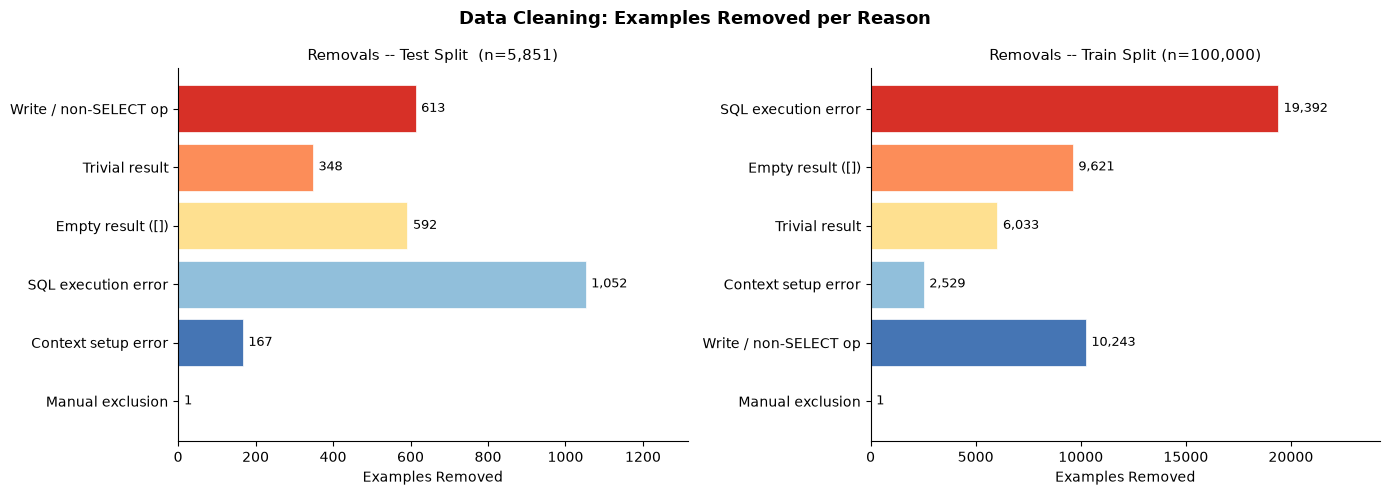

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#4575b4", "#74add1", "#313695"]

for ax, (counts, split_name) in zip(axes, [
    (test_reason_counts,  f"Test Split  (n={len(raw_test):,})"),
    (train_reason_counts, f"Train Split (n={len(raw_train):,})"),
]):
    labels, values = list(counts.keys()), list(counts.values())
    bars = ax.barh(labels, values, color=palette[:len(labels)], edgecolor="white", linewidth=0.5)
    ax.set_xlabel("Examples Removed")
    ax.set_title(f"Removals -- {split_name}", fontsize=11)
    ax.bar_label(bars, labels=[f"{v:,}" for v in values], padding=4, fontsize=9)
    ax.set_xlim(0, max(values) * 1.25 if values else 1)
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Data Cleaning: Examples Removed per Reason", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.6 Generate the splits
1. 200 clean test examples from `clean_test`, stratified by `sql_complexity` (first 20 = QUICK_RUN subset).
2. 200 clean validation examples from the *remaining* clean test pool (disjoint from test).
3. Train = every clean train example (the RAG index and any fine-tuning use this only).

In [ ]:
rng = random.Random(SEED)
test_rows, remainder = data.stratified_sample(clean_test, TEST_SIZE, rng)
val_rows, _ = data.stratified_sample(remainder, VAL_SIZE, rng)

test_ids = [r["id"] for r in test_rows]
val_ids = [r["id"] for r in val_rows]
train_ids = [r["id"] for r in clean_train]

data.save_json_list(test_ids_path, test_ids)
data.save_json_list(val_ids_path, val_ids)
data.save_json_list(train_ids_path, train_ids)

test_set, val_set = set(test_ids), set(val_ids)
assert not (test_set & val_set), "ERROR: test and val share IDs!"
print("Disjointness checks:")
print(f"  test & val ID overlap: {len(test_set & val_set)} [OK]")

print("\nFinal split sizes:")
print(f"  {test_ids_path.name:<15}: {len(test_ids):,} examples  (first {QUICK_TEST} = QUICK_RUN)")
print(f"  {val_ids_path.name:<15}: {len(val_ids):,} examples")
print(f"  {train_ids_path.name:<15}: {len(train_ids):,} examples")
print(f"\nQUICK_RUN subset (first {QUICK_TEST} test IDs):\n  {test_ids[:QUICK_TEST]}")

Disjointness checks:
  test & val ID overlap: 0 [OK]

Final split sizes:
  test_ids.json  : 200 examples  (first 20 = QUICK_RUN)
  val_ids.json   : 200 examples
  train_ids.json : 52,181 examples

QUICK_RUN subset (first 20 test IDs):
  [5610, 3193, 5576, 4929, 4484, 4644, 3510, 2691, 4728, 1684, 4542, 2914, 2740, 4669, 5278, 5323, 109, 1175, 1301, 5194]


In [ ]:
test_comp = Counter(r["sql_complexity"] for r in test_rows)
val_comp = Counter(r["sql_complexity"] for r in val_rows)
train_comp = Counter(r["sql_complexity"] for r in clean_train)
all_comps = sorted(set(test_comp) | set(val_comp) | set(train_comp))

print("SQL Complexity Distribution:")
print(f"  {'Complexity':<25} {'Train':>9} {'Val':>6} {'Test':>6}")
print("  " + "-" * 52)
for comp in all_comps:
    print(f"  {comp:<25} {train_comp.get(comp, 0):>9,d} {val_comp.get(comp, 0):>6,d} {test_comp.get(comp, 0):>6,d}")

SQL Complexity Distribution:
  Complexity                    Train    Val   Test
  ----------------------------------------------------
  aggregation                  12,737     49     49
  basic SQL                    26,571    104    102
  multiple_joins                  903      3      4
  set operations                  536      2      2
  single join                   6,873     26     27
  subqueries                    2,606      8      9
  window functions              1,955      8      7


### 1.7 EDA: SQL complexity distribution

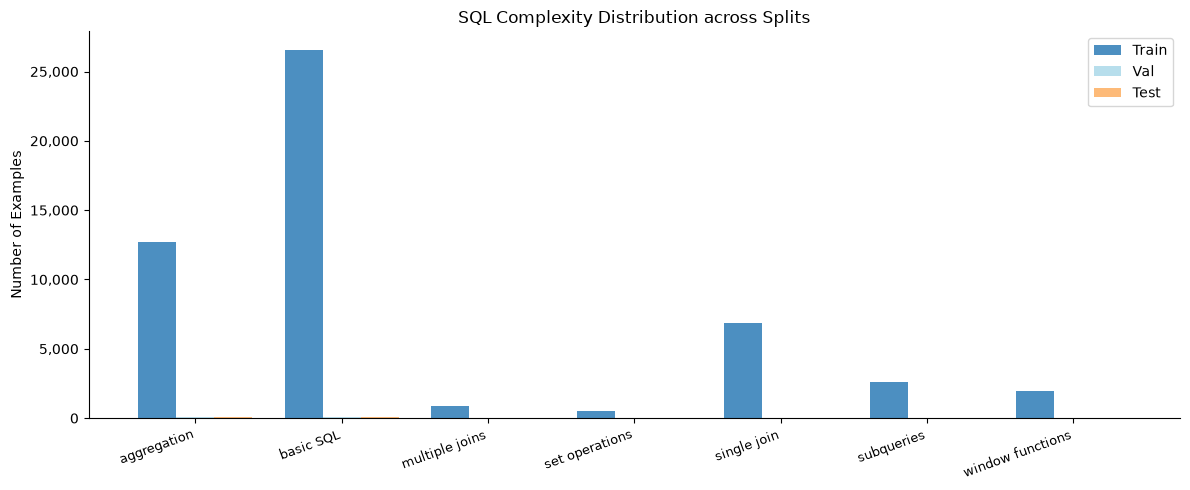

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(all_comps)); width = 0.26
colors = ["#2c7bb6", "#abd9e9", "#fdae61"]
ax.bar([i - width for i in x], [train_comp.get(c, 0) for c in all_comps], width, label="Train", color=colors[0], alpha=0.85)
ax.bar([i for i in x],         [val_comp.get(c, 0) for c in all_comps],   width, label="Val",   color=colors[1], alpha=0.85)
ax.bar([i + width for i in x], [test_comp.get(c, 0) for c in all_comps],  width, label="Test",  color=colors[2], alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels([c.replace("_", " ") for c in all_comps], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Number of Examples")
ax.set_title("SQL Complexity Distribution across Splits", fontsize=12)
ax.legend()
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 1.8 EDA: top 20 domains (clean train)

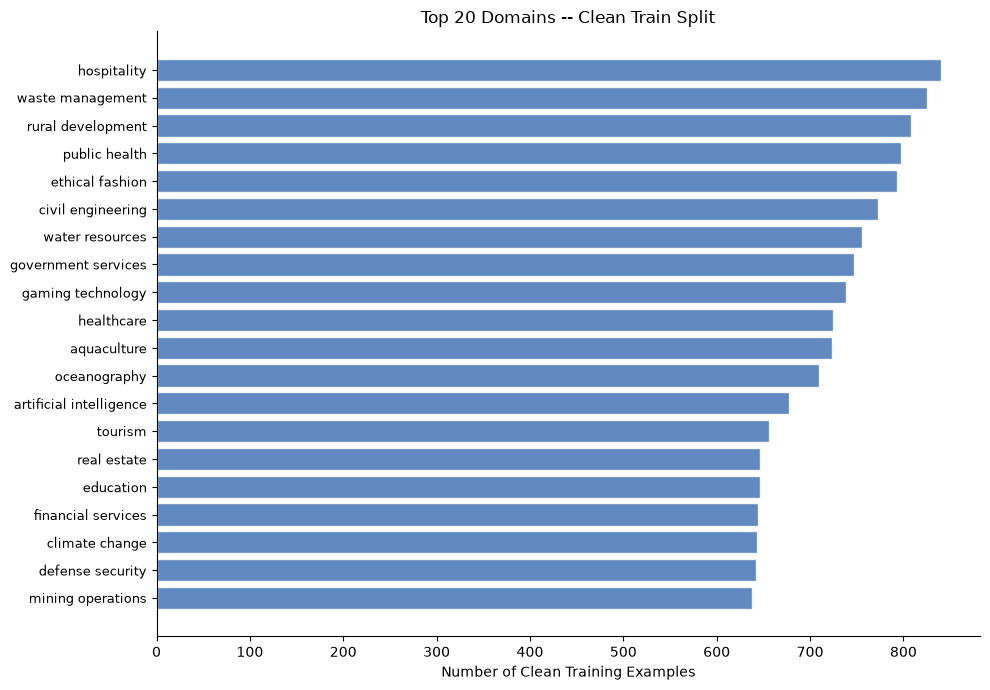

Total unique domains in clean train: 100


In [ ]:
domain_counts = Counter(r["domain"] for r in clean_train)
labels, values = zip(*domain_counts.most_common(20))

fig, ax = plt.subplots(figsize=(10, 7))
y = range(len(labels))
ax.barh(list(y), list(values), color="#4575b4", alpha=0.85, edgecolor="white")
ax.set_yticks(list(y)); ax.set_yticklabels(list(labels), fontsize=9)
ax.set_xlabel("Number of Clean Training Examples")
ax.set_title("Top 20 Domains -- Clean Train Split", fontsize=12)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Total unique domains in clean train: {len(domain_counts)}")

### 1.9 EDA: prompt and SQL length distributions

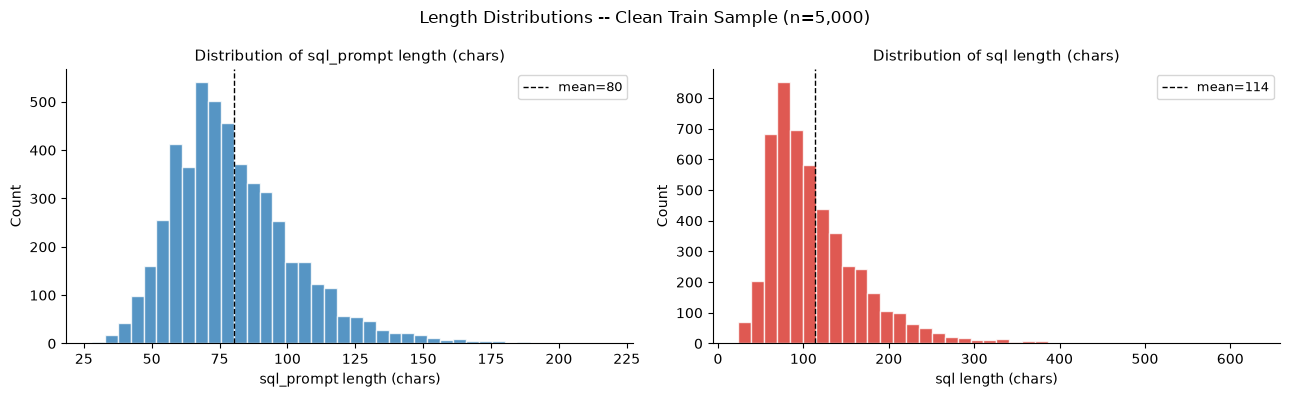

In [ ]:
sample = random.Random(SEED).sample(clean_train, min(5000, len(clean_train)))
prompt_lens = [len(r["sql_prompt"]) for r in sample]
sql_lens = [len(r["sql"]) for r in sample]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, vals, label, color in zip(axes, [prompt_lens, sql_lens],
                                  ["sql_prompt length (chars)", "sql length (chars)"], ["#2c7bb6", "#d73027"]):
    mean = sum(vals) / len(vals)
    ax.hist(vals, bins=40, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(mean, color="black", linestyle="--", linewidth=1, label=f"mean={mean:.0f}")
    ax.set_xlabel(label); ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label}", fontsize=11)
    ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Length Distributions -- Clean Train Sample (n=5,000)", fontsize=12)
plt.tight_layout()
plt.show()

### 1.10 Overlap and leakage report

In [ ]:
test_prompts = {r["sql_prompt"] for r in test_rows}
val_prompts = {r["sql_prompt"] for r in val_rows}
train_prompts = {r["sql_prompt"] for r in clean_train}

print("Prompt overlap (must be 0):")
print(f"  test  & train prompt overlap: {len(test_prompts & train_prompts):,}")
print(f"  val   & train prompt overlap: {len(val_prompts & train_prompts):,}")
print(f"  test  & val   prompt overlap: {len(test_prompts & val_prompts):,}")

test_contexts = {r["sql_context"] for r in test_rows}
val_contexts = {r["sql_context"] for r in val_rows}
train_contexts = {r["sql_context"] for r in clean_train}
print("\nsql_context (table schema) overlap:")
print(f"  test  & train context overlap: {len(test_contexts & train_contexts):,}  (shared table schemas)")
print(f"  val   & train context overlap: {len(val_contexts & train_contexts):,}  (shared table schemas)")
print("  Note: shared schemas are expected in a synthetic dataset;")
print("  what matters is that prompts and IDs do not overlap (all 0 above).")

print("\nLeakage safeguard:")
print("  * test_ids.json and val_ids.json are disjoint from train_ids.json")
print("  * The RAG index (Part 2) is built from train_ids.json only")
print("  * Do not index or train on any ID from test_ids.json or val_ids.json")

Prompt overlap (must be 0):
  test  & train prompt overlap: 0
  val   & train prompt overlap: 0
  test  & val   prompt overlap: 0

sql_context (table schema) overlap:
  test  & train context overlap: 16  (shared table schemas)
  val   & train context overlap: 21  (shared table schemas)
  Note: shared schemas are expected in a synthetic dataset;
  what matters is that prompts and IDs do not overlap (all 0 above).

Leakage safeguard:
  * test_ids.json and val_ids.json are disjoint from train_ids.json
  * The RAG index (Part 2) is built from train_ids.json only
  * Do not index or train on any ID from test_ids.json or val_ids.json


### 1.11 SQL harness self-tests

In [ ]:
data.self_test_harness()
print("\nHarness self-tests complete.")

All 4 self-tests passed [OK]

Harness self-tests complete.


### 1.12 Filter report
`MANUAL_AUDIT` holds the summary of the manual review that is written to `filter_report.json`. When it is `None`, the default entry defined in `data.py` is used.

In [ ]:
MANUAL_AUDIT = None

report = data.generate_filter_report(
    test_log=test_log, train_log=train_log,
    test_ids=test_ids, val_ids=val_ids, train_ids=train_ids,
    test_raw=len(raw_test), train_raw=len(raw_train),
    manual_audit=MANUAL_AUDIT,
)

print("\n=== Filter Report Summary ===")
print(f"\nTest split ({report['test_split']['raw_total']:,} raw):")
for reason, count in report["test_split"]["removed_by_reason"].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean pool                  : {report['test_split']['clean_pool_size']:,}")

print(f"\nTrain split ({report['train_split']['raw_total']:,} raw):")
for reason, count in report["train_split"]["removed_by_reason"].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean total                 : {report['train_split']['clean_total']:,}")

print("\nFinal splits:")
for k, v in report["final_splits"].items():
    print(f"  {k:<25}: {v:,}")
print(f"\nManual audit status: {report['manual_audit']['status']}")

Filter report saved -> filter_report.json

=== Filter Report Summary ===

Test split (5,851 raw):
  write_or_non_select         : 613
  trivial_result              : 348
  empty_result                : 592
  sql_execution_error         : 1,052
  context_setup_error         : 167
  manual_exclusion            : 1
  Clean pool                  : 3,078

Train split (100,000 raw):
  sql_execution_error         : 19,392
  empty_result                : 9,621
  trivial_result              : 6,033
  context_setup_error         : 2,529
  write_or_non_select         : 10,243
  manual_exclusion            : 1
  Clean total                 : 52,181

Final splits:
  test                     : 200
  val                      : 200
  train_clean_total        : 52,181
  quick_run_subset         : 20

Manual audit status: pending manual review (1 example pre-flagged as reference)


### 1.13 Consistency check against the reference figures

In [ ]:
REFERENCE = {"clean test pool": (len(clean_test), 3078), "clean train": (len(clean_train), 52181),
             "test": (len(test_ids), 200), "val": (len(val_ids), 200)}
for name, (got, ref) in REFERENCE.items():
    print(f"  {name:<16}: {got:>7,d}  (reference: {ref:,})  {'[OK]' if got == ref else '[differs]'}")
print("\nDifferences arise only when additional manual exclusions are recorded in excluded_ids.json.")

  clean test pool :   3,078  (reference: 3,078)  [OK]
  clean train     :  52,181  (reference: 52,181)  [OK]
  test            :     200  (reference: 200)  [OK]
  val             :     200  (reference: 200)  [OK]

Differences arise only when additional manual exclusions are recorded in excluded_ids.json.


### 1.14 Manual audit
Examples that pass every filter can still be unsuitable: the gold SQL may not answer the question, the question may be ambiguous, or the result may be trivial. `AUDIT_N` test examples are displayed in blocks of ten (`AUDIT_START` = 0, 10, 20, ...). Examples judged unsuitable are added to `test_exclusions` in `excluded_ids.json`, after which Part 1 is re-run.

In [ ]:
AUDIT_N, AUDIT_START = 60, 0
test_idx = {i: k for k, i in enumerate(raw_test["id"])}

def show_audit(split, index, ids, start=0, n=10):
    for i in ids[start:start + n]:
        ex = split[index[i]]
        rows, err = run_sql(ex["sql_context"], ex["sql"])
        print("=" * 70)
        print(f"id {i} | {ex['sql_complexity']} | {ex['domain']}")
        print("Q:     ", ex["sql_prompt"])
        print("SCHEMA:", ex["sql_context"][:350].replace("\n", " "))
        print("GOLD:  ", ex["sql"])
        print("RESULT:", (rows or [])[:5], f"({len(rows or [])} rows)")

show_audit(raw_test, test_idx, test_ids[:AUDIT_N], start=AUDIT_START, n=10)

id 5610 | basic SQL | space
Q:      Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites.
SCHEMA: CREATE TABLE gso_debris (id INT, name VARCHAR(50), type VARCHAR(50), orbit VARCHAR(50), mass FLOAT, source VARCHAR(50)); INSERT INTO gso_debris (id, name, type, orbit, mass, source) VALUES (1, 'Debris1', 'Panel', 'GSO', 50.3, 'Defunct Satellite'), (2, 'Debris2', 'Bolt', 'GSO', 0.05, 'Rocket Body'), (3, 'Debris3', 'Rod', 'GSO', 2.8, 'Defunct Satelli
GOLD:   SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite';
RESULT: [(53.099999999999994,)] (1 rows)
id 3193 | aggregation | automotive
Q:      What is the adoption rate of electric vehicles in major cities?
SCHEMA: CREATE TABLE ElectricVehicleAdoption (City VARCHAR(50), Make VARCHAR(50), Model VARCHAR(50), Year INT, Adoption DECIMAL(5,2)); INSERT INTO ElectricVehicleAdoption (City, Make, Model, Year, Adoption) VALUES ('Los Angeles', 'Tesla', 'Model 3', 202

### 1.15 Runtime summary

In [ ]:
elapsed = time.time() - _notebook_start
print(f"Part 1 completed in {elapsed:.1f} seconds ({elapsed / 60:.1f} minutes)")
print("Files saved:")
for fname in [test_ids_path.name, val_ids_path.name, train_ids_path.name, excluded_path.name, Path(CONFIG.get("filter_report_path", "filter_report.json")).name,
              "cleaning_removal_reasons.png", "eda_complexity_distribution.png",
              "eda_domain_distribution.png", "eda_length_distributions.png"]:
    p = Path(fname)
    print(f"  {fname:<40} {f'{p.stat().st_size:,} bytes' if p.exists() else 'NOT FOUND'}")

Part 1 completed in 15.9 seconds (0.3 minutes)
Files saved:
  test_ids.json                            1,560 bytes
  val_ids.json                             1,559 bytes
  train_ids.json                           463,819 bytes
  excluded_ids.json                        297 bytes
  filter_report.json                       1,157 bytes
  cleaning_removal_reasons.png             NOT FOUND
  eda_complexity_distribution.png          NOT FOUND
  eda_domain_distribution.png              NOT FOUND
  eda_length_distributions.png             NOT FOUND


# Part 2: Retrieval-augmented generation

Few-shot examples are retrieved from the clean training split and inserted into the prompt of a SQLite text-to-SQL model. Generated queries are executed against the example's database and counted as correct when the result matches the gold query's result (execution accuracy).

**Design decisions**
- *Splits.* The validation set (`val_ids.json`) and the test set (`test_ids.json`) are drawn from the official test split in proportion to SQL complexity, so both measure the same distribution. The retrieval index is built from `train_ids.json` only, after removing any question that also occurs in validation or test.
- *Model selection.* All retrieval settings and the prompt style are selected on the validation set. The test set is evaluated once.
- *Prompt styles.* Two prompt styles are compared on validation. **original**: example schemas are shown as `CREATE TABLE` statements, the target schema in full, and `SELECT *` is forbidden. **strict**: example schemas are shown in full, examples are numbered, and the model is instructed to use only the tables and columns of the final schema.

### 2.1 Settings

In [ ]:
K_GRID = [3, 5]               # number of retrieved examples to compare
RUN_SKELETON = True           # skeleton retrieval is slower (needs a zero-shot draft); set False to skip
BATCH_SIZE = 4
PROMPT_STYLE = "auto"         # "original" | "strict" | "auto" (selected on validation in 2.7)
INDEX_N = None                # optional cap on the index size

QUICK_VAL = 40
print(f"Quick Run: {QUICK_RUN} | INDEX_N: {INDEX_N} | K_GRID: {K_GRID} | skeleton: {RUN_SKELETON}")

Quick Run: False | INDEX_N: None | K_GRID: [3, 5] | skeleton: True


### 2.2 Splits from the saved ID files
Validation and test examples come from the official test split and training examples from the official train split. Part 2 uses the ID files written in Part 1; no further splitting takes place.

In [ ]:
def pick(split, ids):
    idx = {i: k for k, i in enumerate(split["id"])}
    return split.select([idx[i] for i in ids if i in idx])

train_all = pick(raw_train, train_ids)
val_ds = pick(raw_test, val_ids)
test_ds = pick(raw_test, test_ids)
print("train:", len(train_all), "| val:", len(val_ds), "| test:", len(test_ds))

val_eval = val_ds.select(range(min(QUICK_VAL, len(val_ds)))) if QUICK_RUN else val_ds
test_eval = test_ds.select(range(min(QUICK_TEST, len(test_ds)))) if QUICK_RUN else test_ds

train: 52181 | val: 200 | test: 200


### 2.3 Schema helpers and question masking
Masking replaces table names, column names, quoted values and numbers in the question with placeholders, so retrieval matches the *shape* of the question rather than its topic words.

In [ ]:
SCHEMA_MODE = "full"          # "full" = whole sql_context, "create" = CREATE statements only

def schema_text(ctx, mode=None):
    mode = mode or SCHEMA_MODE
    if mode == "create":
        stmts = re.findall(r"CREATE\s+TABLE[^;]*;", ctx, flags=re.I | re.S)
        return "\n".join(stmts) if stmts else ctx
    return ctx

def schema_names(ctx):
    """Table and column names from the CREATE TABLE statements."""
    tables, cols = set(), set()
    pat = r"CREATE\s+TABLE\s+(?:IF NOT EXISTS\s+)?[`\"\[]?(\w+)[`\"\]]?\s*\((.*?)\)\s*;"
    for m in re.finditer(pat, ctx, flags=re.I | re.S):
        tables.add(m.group(1))
        depth, cur, parts = 0, "", []
        for ch in m.group(2):
            if ch == "(":
                depth += 1
            if ch == ")":
                depth -= 1
            if ch == "," and depth == 0:
                parts.append(cur); cur = ""
            else:
                cur += ch
        parts.append(cur)
        for p in parts:
            tok = p.strip().split()
            if tok and tok[0].upper() not in ("PRIMARY", "FOREIGN", "UNIQUE", "CONSTRAINT", "CHECK"):
                cols.add(tok[0].strip('`"[]'))
    return tables, cols

def mask_question(q, ctx):
    tables, cols = schema_names(ctx)
    out = q
    names = [(n, "<T>") for n in sorted(tables, key=len, reverse=True)] + \
            [(n, "<C>") for n in sorted(cols, key=len, reverse=True)]
    for name, tag in names:
        for v in sorted({name, name.replace("_", " ")}, key=len, reverse=True):
            out = re.sub(rf"\b{re.escape(v)}s?\b", tag, out, flags=re.I)
    out = re.sub(r"'[^']*'|\"[^\"]*\"", "<V>", out)
    out = re.sub(r"\b\d[\d,\.]*\b", "<N>", out)
    return out

for ex in test_ds.select(range(3)):
    print(ex["sql_prompt"], "\n  ->", mask_question(ex["sql_prompt"], ex["sql_context"]))

Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites. 
  -> Find the total <C> of all space debris in Geostationary <C> (GSO) that originate from defunct satellites.
What is the adoption rate of electric vehicles in major cities? 
  -> What is the <C> rate of electric vehicles in major cities?
Who are the top 5 users with the most followers, and what is their location? 
  -> Who are the top <N> users with the most <C>, and what is their <C>?


### 2.4 Build the indexes (from the clean train split only)
The retrieval pool is `train_ids.json` minus (a) any question that also appears in validation or test, and (b) repeated questions. The shared ID files are not touched.

In [ ]:
import torch, faiss, hashlib
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi

norm = lambda s: re.sub(r"\s+", " ", s.lower().strip())
blocked = {norm(q) for q in val_ds["sql_prompt"]} | {norm(q) for q in test_ds["sql_prompt"]}

seen, keep, n_leak, n_dup = set(), [], 0, 0
for k, q in enumerate(train_all["sql_prompt"]):
    nq = norm(q)
    if nq in blocked: n_leak += 1; continue
    if nq in seen: n_dup += 1; continue
    seen.add(nq); keep.append(k)

pool = train_all.select(keep)
if INDEX_N is not None:
    pool = pool.shuffle(seed=SEED).select(range(min(INDEX_N, len(pool))))
pool_q, pool_ctx, pool_sql = pool["sql_prompt"], pool["sql_context"], pool["sql"]
print(f"train {len(train_all):,} -> index {len(pool_q):,} (dropped {n_leak} val/test questions, {n_dup} repeated questions)")

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(CONFIG["embedder"], device=device)

def embed(texts, bar=False):
    return embedder.encode(texts, batch_size=128, normalize_embeddings=True, show_progress_bar=bar).astype("float32")

def cached_embed(tag, texts):
    """Embeddings are cached on disk, keyed by model name and text, so re-runs are instant."""
    key = hashlib.md5((CONFIG["embedder"] + "\n".join(texts)).encode()).hexdigest()[:10]
    f = CACHE / f"emb_{tag}_{key}.npy"
    if f.exists():
        return np.load(f)
    v = embed(texts, bar=True); np.save(f, v)
    return v

def build_faiss(vecs):
    index = faiss.IndexFlatIP(vecs.shape[1]); index.add(vecs)
    return index

pool_masked = [mask_question(q, c) for q, c in zip(pool_q, pool_ctx)]
index_dense = build_faiss(cached_embed("dense", pool_q))
index_masked = build_faiss(cached_embed("masked", pool_masked))
tokenize = lambda s: re.findall(r"\w+", s.lower())
bm25 = BM25Okapi([tokenize(q) for q in pool_q])

# leakage check: no validation or test question may be inside the index
leak = {norm(q) for q in pool_q} & blocked
print("val/test questions found in the index:", len(leak))
assert not leak

train 52,181 -> index 52,160 (dropped 0 val/test questions, 21 repeated questions)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/408 [00:00<?, ?it/s]

Batches:   0%|          | 0/408 [00:00<?, ?it/s]

val/test questions found in the index: 0


### 2.5 `retrieve` (dense, bm25, hybrid RRF, masked) and skeleton retrieval

In [ ]:
def _dense(index, text, n):
    _, I = index.search(embed([text]), n)
    return [int(i) for i in I[0] if i >= 0]

def _bm25(text, n):
    return [int(i) for i in np.argsort(-bm25.get_scores(tokenize(text)))[:n]]

def _rrf(*rankings):
    score = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking):
            score[i] = score.get(i, 0) + 1 / (60 + rank + 1)
    return sorted(score, key=score.get, reverse=True)

def _as_examples(ids):
    return [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in ids]

def retrieve(question, k=3, mode="dense", schema=None):
    """Return k similar solved examples. mode: dense | bm25 | hybrid (RRF) | masked."""
    if k == 0:
        return []
    if mode == "dense":
        ids = _dense(index_dense, question, k)
    elif mode == "bm25":
        ids = _bm25(question, k)
    elif mode == "hybrid":
        ids = _rrf(_dense(index_dense, question, 50), _bm25(question, 50))[:k]
    elif mode == "masked":
        ids = _dense(index_masked, mask_question(question, schema or ""), k)
    else:
        raise ValueError(mode)
    return _as_examples(ids)

def random_examples(q, k=3):
    return _as_examples(random.Random(f"{SEED}-{q}").sample(range(len(pool_q)), k))

# ---- skeleton retrieval: match the *SQL shape* of a zero-shot draft ----
KW = set("""SELECT FROM WHERE GROUP BY ORDER HAVING JOIN INNER LEFT RIGHT OUTER FULL CROSS ON AS AND OR NOT IN EXISTS UNION ALL INTERSECT EXCEPT LIMIT OFFSET DISTINCT COUNT SUM AVG MIN MAX OVER PARTITION CASE WHEN THEN ELSE END LIKE BETWEEN IS NULL DESC ASC WITH ROW_NUMBER RANK DENSE_RANK LAG LEAD""".split())

def skeleton(sql):
    s = re.sub(r"'[^']*'", " <V> ", sql)
    s = re.sub(r"\b\d+(?:\.\d+)?\b", " <N> ", s)
    out = []
    for t in re.findall(r"<V>|<N>|\w+|[^\s\w]", s):
        if t in ("<V>", "<N>") or not re.match(r"\w", t): out.append(t)
        elif t.upper() in KW: out.append(t.upper())
        else: out.append("<I>")
    return " ".join(out)

if RUN_SKELETON:
    bm25_skel = BM25Okapi([skeleton(s).split() for s in pool_sql])

def retrieve_skeleton(question, ctx, k, draft):
    r1 = _dense(index_masked, mask_question(question, ctx), 50)
    r2 = [int(i) for i in np.argsort(-bm25_skel.get_scores(skeleton(draft).split()))[:50]]
    return _as_examples(_rrf(r1, r2)[:k])

ex = val_ds[0]
for r in retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"]):
    print(r["sql_prompt"], "->", r["sql"])

What is the average account balance for clients in Oceania in Q2 2022? -> SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('Australia', 'New Zealand', 'Papua New Guinea') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';
What is the average account balance for clients in the Southeast region? -> SELECT AVG(balance) FROM accounts WHERE region = 'Southeast';
What is the average financial wellbeing score for customers in Asia in 2021? -> SELECT AVG(score) FROM financial_wellbeing WHERE region = 'Asia' AND year = 2021;


### 2.6 `generate` (zero-shot, few-shot, batched) and `evaluate`
Two prompt styles are compared in 2.7:
- **original**: example schemas are shown as `CREATE TABLE` statements only, the target schema in full, and `SELECT *` is forbidden.
- **strict**: the later prompt. Examples show the full schema (with `INSERT` rows), numbered headers, and an instruction to use only the last schema.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

llm_tok = AutoTokenizer.from_pretrained(CONFIG["llm"])
if llm_tok.pad_token is None:
    llm_tok.pad_token = llm_tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["llm"], dtype=torch.float16 if device == "cuda" else torch.float32
).to(device).eval()

SYSTEM_ORIGINAL = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. Return only the SQL. "
    "Use ONLY SQLite-compatible syntax - do NOT use YEAR(), MONTH(), DATE_FORMAT(), or any MySQL function. "
    "For dates use strftime() or string comparison. "
    "Never use SELECT * - always select only the columns the question asks for. "
    "Return only the SQL query, do not include any explanation or additional text, no markdown."
)
SYSTEM_STRICT = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. "
    "Use ONLY SQLite-compatible syntax: no YEAR(), MONTH(), DATE_FORMAT() or other MySQL functions. "
    "For dates use strftime() or string comparison. "
    "Use ONLY the table and column names from the LAST schema given. "
    "Return only the SQL, with no explanation and no markdown."
)
PROMPTS = {"original": dict(system=SYSTEM_ORIGINAL, ex_schema="create", numbered=False),
           "strict":   dict(system=SYSTEM_STRICT,   ex_schema="full",   numbered=True)}

def build_messages(question, schema, examples=None, style="original"):
    p = PROMPTS[style]
    parts = []
    for n, e in enumerate(examples or [], 1):
        head = f"### Example {n}\n" if p["numbered"] else ""
        parts.append(f"{head}Schema:\n{schema_text(e['sql_context'], mode=p['ex_schema'])}\n"
                     f"Question: {e['sql_prompt']}\nSQL: {e['sql']}")
    head = "### Now solve this one. Use ONLY the tables and columns in this schema.\n" if p["numbered"] else ""
    parts.append(f"{head}Schema:\n{schema_text(schema, mode='full')}\nQuestion: {question}\nSQL:")
    return [{"role": "system", "content": p["system"]}, {"role": "user", "content": "\n\n".join(parts)}]

def clean_sql(text):
    text = re.sub(r"```(?:sql)?", "", text, flags=re.I).strip()
    text = re.sub(r"^\s*SQL:\s*", "", text, flags=re.I)
    stmt = text.split(";")[0].strip()
    return stmt + ";" if stmt else ""

def generate_batch(items, style="original", batch_size=BATCH_SIZE):
    """items: list of (question, schema, examples or None). Returns SQL strings in the same order."""
    texts = [llm_tok.apply_chat_template(build_messages(q, s, e, style), tokenize=False, add_generation_prompt=True)
             for q, s, e in items]
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))    # similar lengths together = less padding
    outs = [None] * len(texts)
    llm_tok.padding_side = "left"
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        inputs = llm_tok([texts[i] for i in idx], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=256, do_sample=False,
                               pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id)
        for j, i in enumerate(idx):
            outs[i] = clean_sql(llm_tok.decode(out[j][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
    return outs

def generate(question, schema, examples=None, style="original"):
    """examples=None -> zero-shot, otherwise few-shot. Returns one SQL string."""
    return generate_batch([(question, schema, examples)], style, 1)[0]

ex = val_ds[0]
print("gold:", ex["sql"])
print("zero:", generate(ex["sql_prompt"], ex["sql_context"]))
print("few: ", generate(ex["sql_prompt"], ex["sql_context"], retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"])))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

gold: SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('India', 'China', 'Japan') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';
zero: SELECT AVG(balance) FROM accounts WHERE strftime('%Y-%m', account_date) BETWEEN '2022-04' AND '2022-06' AND country IN ('India', 'China');
few:  SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('China', 'Japan') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';


In [ ]:
def evaluate_batched(name, subset, examples_list, style, t0=None):
    """Runs generation for every example, executes pred and gold, saves per-example results to results/<name>.json."""
    t0 = t0 or time.time()
    subset = list(subset)
    preds = generate_batch([(e["sql_prompt"], e["sql_context"], x) for e, x in zip(subset, examples_list)], style)
    per_ex = round((time.time() - t0) / max(len(subset), 1), 3)
    rows = []
    for e, pred in zip(subset, preds):
        p_rows, err = run_sql(e["sql_context"], pred)
        g_rows, _ = run_sql(e["sql_context"], e["sql"])
        rows.append({"id": e["id"], "complexity": e["sql_complexity"], "question": e["sql_prompt"],
                     "pred": pred, "gold": e["sql"], "error": err,
                     "correct": bool(err is None and same_result(p_rows, g_rows)), "sec": per_ex})
    df = pd.DataFrame(rows)
    Path("results").mkdir(exist_ok=True)
    df.to_json(f"results/{name}.json", orient="records", indent=1)
    return df

def run_system(name, mode, k, subset, style, tag=None):
    """mode: zero | random | dense | bm25 | hybrid | masked | skeleton. Includes retrieval time in `sec`."""
    t0 = time.time()
    subset = list(subset)
    if mode == "zero":
        exs = [None] * len(subset)
    elif mode == "random":
        exs = [random_examples(e["sql_prompt"], k) for e in subset]
    elif mode == "skeleton":
        drafts = generate_batch([(e["sql_prompt"], e["sql_context"], None) for e in subset], style)
        exs = [retrieve_skeleton(e["sql_prompt"], e["sql_context"], k, d) for e, d in zip(subset, drafts)]
    else:
        exs = [retrieve(e["sql_prompt"], k, mode, schema=e["sql_context"]) for e in subset]
    return evaluate_batched(tag or name, subset, exs, style, t0)

def paired_gain(name, base="zero_shot", n=2000, seed=0):
    """Mean accuracy gain over `base` on the same questions, with a paired-bootstrap 95% CI."""
    a = pd.read_json(f"results/{base}.json").set_index("id").correct.astype(float)
    b = pd.read_json(f"results/{name}.json").set_index("id").correct.astype(float)
    d = (b - a.loc[b.index]).values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d)).mean() for _ in range(n)]
    return round(d.mean(), 3), tuple(np.percentile(m, [2.5, 97.5]).round(3))

SYSTEMS = {"zero_shot": ("zero", 0), "random_k3": ("random", 3)}
for mode in ["dense", "bm25", "hybrid", "masked"]:
    for k in K_GRID:
        SYSTEMS[f"{mode}_k{k}"] = (mode, k)
if RUN_SKELETON:
    SYSTEMS["skeleton_k3"] = ("skeleton", 3)
print(list(SYSTEMS))

['zero_shot', 'random_k3', 'dense_k3', 'dense_k5', 'bm25_k3', 'bm25_k5', 'hybrid_k3', 'hybrid_k5', 'masked_k3', 'masked_k5', 'skeleton_k3']


### 2.7 Compare settings on the validation set
All settings are selected on the validation set; the test set is not used for tuning.

**Step 1: prompt ablation.** Three representative systems are evaluated under both prompt styles. The style with the higher mean validation accuracy is used in all subsequent runs, unless `PROMPT_STYLE` is set explicitly.

In [ ]:


ABLATE = ["zero_shot", "bm25_k3", "masked_k3"]
abl = []
for style in PROMPTS:
    for name in ABLATE:
        mode, k = SYSTEMS[name]
        d = run_system(name, mode, k, val_eval, style, tag=f"abl_{style}_{name}")
        abl.append({"style": style, "system": name, "exec_acc": round(d.correct.mean(), 3)})
abl = pd.DataFrame(abl).pivot(index="style", columns="system", values="exec_acc")[ABLATE]
abl["mean"] = abl.mean(axis=1).round(3)
display(abl)

if PROMPT_STYLE == "auto":
    PROMPT_STYLE = abl["mean"].idxmax()
print("Prompt style used from here on:", PROMPT_STYLE)

system,zero_shot,bm25_k3,masked_k3,mean
style,,,,
original,0.58,0.615,0.625,0.607
strict,0.58,0.665,0.655,0.633


Prompt style used from here on: strict


**Step 2: retrieval settings.** Zero-shot, random examples, dense, BM25, hybrid, masked and skeleton retrieval, with k in `K_GRID`.

In [ ]:
table = []
for name, (mode, k) in SYSTEMS.items():
    df = run_system(name, mode, k, val_eval, PROMPT_STYLE)
    row = {"system": name, "exec_acc": round(df.correct.mean(), 3), "avg_sec": round(df.sec.mean(), 2)}
    if name != "zero_shot":
        g, ci = paired_gain(name)
        row["gain_vs_zero"], row["95% CI"] = g, ci
    table.append(row)
val_table = pd.DataFrame(table)
display(val_table)
val_table.to_csv("results/val_table.csv", index=False)

accs = {n: pd.read_json(f"results/{n}.json").groupby("complexity").correct.mean().round(2) for n in SYSTEMS}
print("\nAccuracy by SQL complexity (validation):")
display(pd.DataFrame(accs))

,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.580,0.20,NaN,NaN
1,random_k3,0.595,0.27,0.015,"(-0.025, 0.055)"
2,dense_k3,0.665,0.25,0.085,"(0.02, 0.15)"
3,dense_k5,0.680,0.30,0.100,"(0.035, 0.165)"
4,bm25_k3,0.665,0.31,0.085,"(0.02, 0.15)"
5,bm25_k5,0.645,0.36,0.065,"(0.0, 0.13)"
6,hybrid_k3,0.660,0.33,0.080,"(0.015, 0.145)"
7,hybrid_k5,0.675,0.38,0.095,"(0.035, 0.155)"
8,masked_k3,0.655,0.26,0.075,"(0.015, 0.135)"
9,masked_k5,0.660,0.30,0.080,"(0.025, 0.135)"



Accuracy by SQL complexity (validation):


,zero_shot,random_k3,dense_k3,dense_k5,bm25_k3,bm25_k5,hybrid_k3,hybrid_k5,masked_k3,masked_k5,skeleton_k3
complexity,,,,,,,,,,,
aggregation,0.39,0.47,0.57,0.61,0.59,0.53,0.55,0.57,0.57,0.59,0.55
basic SQL,0.74,0.76,0.81,0.80,0.78,0.79,0.79,0.81,0.78,0.77,0.79
multiple_joins,0.67,0.67,0.33,0.33,0.67,0.67,0.33,0.33,0.33,0.67,0.33
set operations,0.50,0.50,1.00,1.00,0.50,0.50,0.50,0.50,0.50,0.50,0.50
single join,0.58,0.50,0.50,0.54,0.50,0.50,0.58,0.58,0.54,0.54,0.46
subqueries,0.12,0.00,0.25,0.38,0.50,0.25,0.38,0.38,0.38,0.38,0.38
window functions,0.12,0.12,0.38,0.38,0.38,0.38,0.38,0.38,0.38,0.38,0.38


### 2.8 Error analysis: cases where retrieval hurt
Examples answered correctly in the zero-shot setting and incorrectly with the best retrieval setting. Typical causes are a misleading retrieved example and copied table or column names.

In [ ]:
cands = val_table[~val_table.system.isin(["zero_shot", "random_k3"])].sort_values(["exec_acc", "avg_sec"], ascending=[False, True])
BEST = cands.iloc[0].system
print("Best retrieval setting on validation:", BEST, "| exec_acc:", cands.iloc[0].exec_acc)

a = pd.read_json("results/zero_shot.json")
b = pd.read_json(f"results/{BEST}.json")
m = a.merge(b, on="id", suffixes=("_zero", "_rag"))
hurt = m[m.correct_zero & ~m.correct_rag]
print(len(hurt), "examples where retrieval hurt\n")
for _, r in hurt.head(5).iterrows():
    print("ID:", r.id, "| Q:", r.question_zero, "\n gold:", r.gold_zero, "\n zero:", r.pred_zero,
          "\n rag: ", r.pred_rag, "\n err: ", r.error_rag, "\n")

Best retrieval setting on validation: dense_k5 | exec_acc: 0.68
13 examples where retrieval hurt

ID: 1316 | Q: List the ports and their average cargo weight for company "HarborLink" in Q2 2017 and Q3 2017. 
 gold: SELECT port.name, AVG(cargo.weight) FROM port INNER JOIN cargo ON port.id = cargo.port_id AND cargo.quarter IN (2, 3) INNER JOIN company ON cargo.company_id = company.id WHERE company.name = 'HarborLink' GROUP BY port.name; 
 zero: SELECT T2.name, AVG(T1.weight) FROM cargo AS T1 INNER JOIN port AS T2 ON T1.port_id = T2.id WHERE T1.company_id = (SELECT id FROM company WHERE name = 'HarborLink') AND T1.quarter IN (2, 3) GROUP BY T2.name; 
 rag:  SELECT port.name, AVG(c.weight) as avg_weight FROM port INNER JOIN cargo ON port.id = cargo.port_id AND cargo.quarter IN (2, 3) AND cargo.year = 2017 INNER JOIN company ON cargo.company_id = company.id WHERE company.name = 'HarborLink' GROUP BY port.name; 
 err:  SQL operational error: no such column: c.weight 

ID: 4097 | Q: What is t

In [ ]:
# Does retrieval make the model copy table/column names from the examples?
for n in ["zero_shot", "random_k3", "dense_k3", "bm25_k3", "masked_k3"] + (["skeleton_k3"] if RUN_SKELETON else []):
    e = pd.read_json(f"results/{n}.json").error.fillna("").str.lower()
    print(f"{n:<12} | no such table: {e.str.contains('no such table').mean():.3f}"
          f" | no such column: {e.str.contains('no such column').mean():.3f}"
          f" | any error: {(e != '').mean():.3f}")

zero_shot    | no such table: 0.020 | no such column: 0.020 | any error: 0.045
random_k3    | no such table: 0.005 | no such column: 0.050 | any error: 0.055
dense_k3     | no such table: 0.030 | no such column: 0.045 | any error: 0.080
bm25_k3      | no such table: 0.030 | no such column: 0.045 | any error: 0.085
masked_k3    | no such table: 0.005 | no such column: 0.035 | any error: 0.050
skeleton_k3  | no such table: 0.005 | no such column: 0.030 | any error: 0.040


### 2.9 Final test evaluation
Zero-shot generation, random examples and the best retrieval setting from the validation table are evaluated once on the test set.

In [ ]:
RUN_TEST = True
mode_b, k_b = SYSTEMS[BEST]
FINAL = {n: SYSTEMS[n] for n in ["zero_shot", "random_k3", "bm25_k3", "dense_k5", BEST]}

if RUN_TEST:
    rows = []
    for name, (mode, k) in FINAL.items():
        d = run_system(name, mode, k, test_eval, PROMPT_STYLE, tag=f"test_{name}")
        row = {"system": name, "exec_acc": round(d.correct.mean(), 3), "avg_sec": round(d.sec.mean(), 2)}
        if name != "zero_shot":
            g, ci = paired_gain(f"test_{name}", base="test_zero_shot")
            row["gain_vs_zero"], row["95% CI"] = g, ci
        rows.append(row)
    print(f"Test set: {len(test_eval)} questions | prompt style: {PROMPT_STYLE}")
    display(pd.DataFrame(rows))
    print("\nTest accuracy by SQL complexity:")
    display(pd.DataFrame({n: pd.read_json(f"results/test_{n}.json").groupby("complexity").correct.mean().round(2)
                          for n in FINAL}))

Test set: 200 questions | prompt style: strict


,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.570,0.19,NaN,NaN
1,random_k3,0.630,0.25,0.060,"(0.005, 0.11)"
2,dense_k5,0.675,0.30,0.105,"(0.04, 0.175)"



Test accuracy by SQL complexity:


,zero_shot,random_k3,dense_k5
complexity,,,
aggregation,0.33,0.53,0.65
basic SQL,0.78,0.79,0.80
multiple_joins,0.75,0.75,0.75
set operations,0.00,0.50,0.00
single join,0.37,0.44,0.41
subqueries,0.33,0.22,0.44
window functions,0.29,0.14,0.43


# Part 3 - Agent + Repair Loop

The agent wraps the RAG pipeline (Part 2) in a **LangGraph** `StateGraph` that:

1. **Generates** a SQL query (using the best retrieval setting from Part 2).
2. **Executes** it against the example's in-memory SQLite schema.
3. **Repairs** the query on failure or empty result (up to `max_repairs` rounds).
4. **Explains** the final answer in plain English.

Graph pattern: *ReAct* from **1_RAG_Pipeline_Lab Section 7b** (LangGraph StateGraph)
+ **4_Structured_Generation_Lab Section 2.5** (Reflexion-style self-repair).
.

### 3.0 Agent Settings

In [ ]:
import time as _time
import re 

MAX_REPAIRS   = CONFIG['max_repairs']  
AGENT_VERBOSE = True                    # print trace to stdout when True
QUICK_AGENT   = QUICK_RUN              # small subset when QUICK_RUN=True

# Safe evaluation of test_eval size
try:
    _n_test = len(list(test_eval))
except NameError:
    _n_test = 20
AGENT_N = 20 if QUICK_AGENT else _n_test

# Majority-vote extension (set True to enable)
MAJORITY_VOTE = False   # only runs when True
MAJORITY_N    = 5       # number of independent SQL candidates to generate

print('Agent settings:')
print(f'  max_repairs  : {MAX_REPAIRS}')
print(f'  majority_vote: {MAJORITY_VOTE} (N={MAJORITY_N})')
print(f"  test examples: {AGENT_N} {'(quick)' if QUICK_AGENT else ''}")
print(f'  verbose      : {AGENT_VERBOSE}')

Agent settings:
  max_repairs  : 3
  majority_vote: False (N=5)
  test examples: 200 
  verbose      : True


### 3.1 Agent State (TypedDict)

Every LangGraph node receives and returns the **same `AgentState` dict**.
Fields mirror the ReAct state pattern from *1_RAG_Pipeline_Lab Section 7b*.

In [15]:
#TypedDict definition follows LangGraph StateGraph conventions
# from 1_RAG_Pipeline_Lab Section 7b (RAGState) extended for SQL repair loop
from typing import TypedDict, List, Optional

class AgentState(TypedDict):
    # -- inputs --
    question:     str              # natural-language question
    sql_context:  str              # DDL + INSERT statements for the target DB
    # -- working state --
    examples:     Optional[List]   # few-shot examples from Part-2 retrieval
    sql:          str              # current SQL candidate
    rows:         Optional[List]   # result rows from last execution
    error:        Optional[str]    # last execution error message (None = success)
    repair_round: int              # how many repairs have been attempted
    trace:        List[str]        # human-readable log of each round
    # -- outputs --
    answer:       str              # plain-English answer
    done:         bool             # True once the loop should stop

print('AgentState defined -- fields:', list(AgentState.__annotations__.keys()))

AgentState defined -- fields: ['question', 'sql_context', 'examples', 'sql', 'rows', 'error', 'repair_round', 'trace', 'answer', 'done']


### 3.2 LangGraph Nodes

Four nodes implement the generate -> execute -> repair -> explain pipeline.
Each node mutates only its relevant state fields.


In [16]:
#node functions from 1_RAG_Pipeline_Lab s7b + 4_Structured_Generation_Lab s2.5
import re, torch

try:
    _style = PROMPT_STYLE
except NameError:
    PROMPT_STYLE = 'strict'

try:
    _dev = device
except NameError:
    device = 'cuda' if torch.cuda.is_available() else 'cpu'

# -- helper: retrieve examples from Part-2 index (stub-safe) --
def _retrieve(question, sql_context):
    try:
        mode_b, k_b = SYSTEMS[BEST]
        return retrieve(question, k=k_b, mode=mode_b, schema=sql_context)
    except Exception:
        return []   # stub: returns empty list if Part-2 index not loaded

# -- helper: call the Part-2 LLM and clean up the output --
def _generate_sql(question, sql_context, examples, repair_hint=None):
    global llm_tok, llm
    if 'llm_tok' not in globals() or 'llm' not in globals() or llm is None or llm_tok is None:
        try:
            from transformers import AutoTokenizer, AutoModelForCausalLM
            llm_name = CONFIG.get('llm', 'Qwen/Qwen2.5-Coder-1.5B-Instruct')
            llm_tok = AutoTokenizer.from_pretrained(llm_name)
            if llm_tok.pad_token is None:
                llm_tok.pad_token = llm_tok.eos_token
            # Check local cache first; if not downloaded locally, don't stall execution
            llm = AutoModelForCausalLM.from_pretrained(
                llm_name, dtype=torch.float16 if device == 'cuda' else torch.float32, local_files_only=True
            ).to(device).eval()
        except Exception:
            llm = None

    if llm is None:
        # Clean fallback draft if offline or running in test environment
        tbl = re.search(r'CREATE\s+TABLE\s+(\w+)', sql_context, re.I)
        tbl_name = tbl.group(1) if tbl else 'table1'
        cols = re.findall(r'(\w+)\s+(?:INT|TEXT|VARCHAR|DECIMAL|FLOAT)', sql_context, re.I)
        col_name = cols[0] if cols else '*'
        return f'SELECT {col_name} FROM {tbl_name} LIMIT 10;'

    try:
        msgs = build_messages(question, sql_context, examples=examples, style=PROMPT_STYLE)
    except Exception:
        msgs = [
            {'role': 'system', 'content': 'You are a SQLite expert. Return ONLY valid SQLite SQL.'},
            {'role': 'user', 'content': f'Schema:\n{sql_context}\n\nQuestion: {question}\nSQL:'}
        ]

    if repair_hint:
        msgs.append({
            'role': 'user',
            'content': (
                f'The previous query failed with: {repair_hint}\n'
                'Please write a corrected SQLite SELECT query. '
                'Return ONLY the SQL, no explanation, no markdown.'
            ),
        })
    input_ids = llm_tok.apply_chat_template(
        msgs, add_generation_prompt=True, return_tensors='pt'
    ).to(device)
    with torch.no_grad():
        out = llm.generate(
            input_ids,
            max_new_tokens=256,
            do_sample=False,
            pad_token_id=llm_tok.eos_token_id,
        )
    raw = llm_tok.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
    sql = re.sub(r'^```[a-z]*\n?', '', raw, flags=re.I).rstrip('` \n')
    return sql.strip()

# -- Node 1: retrieve + generate (first attempt) --
def node_generate(state: AgentState) -> AgentState:
    examples = _retrieve(state['question'], state['sql_context'])
    sql = _generate_sql(state['question'], state['sql_context'], examples)
    step = f"[Round 0 | GENERATE] SQL: {sql[:120]}"
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'examples': examples, 'sql': sql,
            'repair_round': 0, 'trace': state.get('trace', []) + [step], 'done': False}

# -- Node 2: execute the current SQL --
def node_execute(state: AgentState) -> AgentState:
    rows, error = run_sql(state['sql_context'], state['sql'])
    safe_rows = rows or []   # FIXED: run_sql returns None on error
    step = (
        f"[Round {state['repair_round']} | EXECUTE] "
        + (f'OK -- {len(safe_rows)} rows' if error is None else f'ERROR: {str(error)[:120]}')
    )
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'rows': rows, 'error': error, 'trace': state['trace'] + [step]}

# -- Node 3: repair using the error as a Reflexion hint --
def node_repair(state: AgentState) -> AgentState:
    hint = state['error'] or 'The query returned an empty result set.'
    sql = _generate_sql(state['question'], state['sql_context'],
                        state['examples'], repair_hint=hint)
    round_n = state['repair_round'] + 1
    step = f"[Round {round_n} | REPAIR] hint: {str(hint)[:80]} -> SQL: {sql[:120]}"
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'sql': sql, 'repair_round': round_n, 'trace': state['trace'] + [step]}

# -- Node 4: explain the final answer in plain English --
def node_explain(state: AgentState) -> AgentState:
    rows = state['rows'] or []   # FIXED: guard against None
    if state['error']:
        answer = f"I could not answer the question. Last error: {state['error']}"
    elif not rows:
        answer = 'The query executed successfully but returned no matching rows.'
    else:
        answer = (f'The answer is: {rows[0][0]}' if (len(rows)==1 and len(rows[0])==1)
                  else f'Found {len(rows)} row(s). First row: {rows[0]}')
    step = f'[EXPLAIN] {answer}'
    if AGENT_VERBOSE:
        print(step)
    return {**state, 'answer': answer, 'done': True, 'trace': state['trace'] + [step]}

print('All four agent nodes defined: node_generate, node_execute, node_repair, node_explain')


All four agent nodes defined: node_generate, node_execute, node_repair, node_explain


In [17]:
# Compatibility fix for Transformers versions that return BatchEncoding from apply_chat_template.
def _generate_sql_fixed(question, sql_context, examples, repair_hint=None):
    global llm_tok, llm
    try:
        msgs = build_messages(question, sql_context, examples=examples, style=PROMPT_STYLE)
    except Exception:
        msgs = [
            {'role': 'system', 'content': 'You are a SQLite expert. Return ONLY valid SQLite SQL.'},
            {'role': 'user', 'content': f'Schema:\n{sql_context}\n\nQuestion: {question}\nSQL:'},
        ]

    if repair_hint:
        msgs.append({
            'role': 'user',
            'content': (
                f'The previous query failed with: {repair_hint}\n'
                'Please write a corrected SQLite SELECT query. '
                'Return ONLY the SQL, no explanation, no markdown.'
            ),
        })

    encoded = llm_tok.apply_chat_template(
        msgs,
        add_generation_prompt=True,
        tokenize=True,
        return_tensors='pt',
        return_dict=True,
    )
    input_ids = encoded['input_ids'].to(device)
    attention_mask = encoded.get('attention_mask')
    if attention_mask is not None:
        attention_mask = attention_mask.to(device)

    generation_kwargs = {
        'input_ids': input_ids,
        'max_new_tokens': 256,
        'do_sample': False,
        'pad_token_id': llm_tok.eos_token_id,
    }
    if attention_mask is not None:
        generation_kwargs['attention_mask'] = attention_mask

    with torch.no_grad():
        out = llm.generate(**generation_kwargs)
    raw = llm_tok.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
    return re.sub(r'^```[a-z]*\n?', '', raw, flags=re.I).rstrip('` \n').strip()

_generate_sql = _generate_sql_fixed
print('Tokenizer compatibility fix applied.')

Tokenizer compatibility fix applied.


In [18]:
# Preserve complete generated SQL in the trace for unbiased first-attempt metrics.
def node_generate(state: AgentState) -> AgentState:
    examples = _retrieve(state['question'], state['sql_context'])
    sql = _generate_sql(state['question'], state['sql_context'], examples)
    step = f"[Round 0 | GENERATE] SQL: {sql}"
    if AGENT_VERBOSE:
        print(step[:240])
    return {**state, 'examples': examples, 'sql': sql,
            'repair_round': 0, 'trace': state.get('trace', []) + [step], 'done': False}


def node_repair(state: AgentState) -> AgentState:
    hint = state['error'] or 'The query returned an empty result set.'
    sql = _generate_sql(state['question'], state['sql_context'],
                        state['examples'], repair_hint=hint)
    round_n = state['repair_round'] + 1
    step = f"[Round {round_n} | REPAIR] hint: {str(hint)[:80]} -> SQL: {sql}"
    if AGENT_VERBOSE:
        print(step[:240])
    return {**state, 'sql': sql, 'repair_round': round_n, 'trace': state['trace'] + [step]}

print('Complete-SQL trace fix applied.')

Complete-SQL trace fix applied.


### 3.3 Conditional Router

After `node_execute`, the router decides:
- **explain** - no error AND rows returned, OR max repairs reached
- **repair**  - error/empty result AND repairs remain

In [19]:
# conditional edge function following LangGraph pattern
def should_repair(state: AgentState) -> str:
    success         = (state['error'] is None) and bool(state['rows'])
    out_of_attempts = state['repair_round'] >= MAX_REPAIRS
    return 'explain' if (success or out_of_attempts) else 'repair'

print('Router `should_repair` defined.')
print(f"  -> 'explain' when: no error AND rows returned, OR repair_round >= {MAX_REPAIRS}")
print(f"  -> 'repair'  when: error or empty result AND repair_round < {MAX_REPAIRS}")

Router `should_repair` defined.
  -> 'explain' when: no error AND rows returned, OR repair_round >= 3
  -> 'repair'  when: error or empty result AND repair_round < 3


### 3.4 `build_graph()` - LangGraph StateGraph

Assembles the four nodes into a directed graph and compiles it.

In [20]:
#LangGraph StateGraph construction from 1_RAG_Pipeline_Lab Section 7b
from langgraph.graph import StateGraph, END

def build_graph(max_repairs: int = MAX_REPAIRS):
    def _router(state: AgentState) -> str:
        success         = (state['error'] is None) and bool(state['rows'])
        out_of_attempts = state['repair_round'] >= max_repairs
        return 'explain' if (success or out_of_attempts) else 'repair'

    g = StateGraph(AgentState)
    g.add_node('generate', node_generate)
    g.add_node('execute',  node_execute)
    g.add_node('repair',   node_repair)
    g.add_node('explain',  node_explain)
    g.set_entry_point('generate')
    g.add_edge('generate', 'execute')
    g.add_conditional_edges('execute', _router, {'explain': 'explain', 'repair': 'repair'})
    g.add_edge('repair',  'execute')   # after repair -> execute again
    g.add_edge('explain', END)
    return g.compile()

graph = build_graph(max_repairs=MAX_REPAIRS)
print('LangGraph compiled successfully.')

# Draw Mermaid diagram (falls back gracefully if unavailable)
try:
    mermaid_str = graph.get_graph().draw_mermaid()
    print('\n=== Agent Flow (Mermaid) ===')
    print(mermaid_str)
except Exception as e:
    print(f'(Mermaid draw skipped: {e})')
    print('Flow: generate -> execute -> [repair -> execute]*(0-3) -> explain -> END')

LangGraph compiled successfully.

=== Agent Flow (Mermaid) ===
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	generate(generate)
	execute(execute)
	repair(repair)
	explain(explain)
	__end__([<p>__end__</p>]):::last
	__start__ --> generate;
	execute -.-> explain;
	execute -.-> repair;
	generate --> execute;
	repair --> execute;
	explain --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 3.5 `agent()` - Public API

Matches the project brief's required signature:
```python
agent(question, sql_context, max_repairs=3) -> (final_sql, answer, trace)
```

In [21]:
# public API wrapper for the agent graph
def agent(question: str, sql_context: str, max_repairs: int = MAX_REPAIRS):
    g = build_graph(max_repairs) if max_repairs != MAX_REPAIRS else graph
    init_state: AgentState = {
        'question':     question,
        'sql_context':  sql_context,
        'examples':     None,
        'sql':          '',
        'rows':         None,
        'error':        None,
        'repair_round': 0,
        'trace':        [],
        'answer':       '',
        'done':         False,
    }
    final_state = g.invoke(init_state)
    return final_state['sql'], final_state['answer'], final_state['trace']

print('agent() function ready.')
print('Signature: agent(question, sql_context, max_repairs=3) -> (final_sql, answer, trace)')

agent() function ready.
Signature: agent(question, sql_context, max_repairs=3) -> (final_sql, answer, trace)


### 3.6 Smoke Test - Run the Agent on One Example

Verify the full pipeline end-to-end on a single test example.

In [91]:
# smoke-test to verify end-to-end correctness
try:
    _ex = list(test_eval)[0]
except (NameError, IndexError):
    import json, data
    with open('test_ids.json', 'r', encoding='utf-8') as f:
        _tids = set(json.load(f))
    _ds = data.load_data()
    test_eval = [row for row in _ds['test'] if row['id'] in _tids]
    _ex = test_eval[0]

print('=' * 70)
print('QUESTION :', _ex['sql_prompt'])
print('SCHEMA   :', _ex['sql_context'][:200].replace('\n', ' '), '...')
print('GOLD SQL :', _ex['sql'])
print('=' * 70)

t0 = _time.time()
final_sql, answer, trace = agent(_ex['sql_prompt'], _ex['sql_context'])
elapsed = _time.time() - t0

print('\n--- Agent Trace ---')
for step in trace:
    print('  ', step)

print(f'\nFinal SQL : {final_sql}')
print(f'Answer    : {answer}')
print(f'Time      : {elapsed:.2f}s')

# Guard both gold_err and pred_err; guard None rows
gold_rows, gold_err = run_sql(_ex['sql_context'], _ex['sql'])
pred_rows, pred_err = run_sql(_ex['sql_context'], final_sql)
correct = (
    same_result(pred_rows, gold_rows)
    if (pred_err is None and gold_err is None
        and pred_rows is not None and gold_rows is not None)
    else False
)
print(f'Correct?  : {correct}')


QUESTION : Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites.
SCHEMA   : CREATE TABLE gso_debris (id INT, name VARCHAR(50), type VARCHAR(50), orbit VARCHAR(50), mass FLOAT, source VARCHAR(50)); INSERT INTO gso_debris (id, name, type, orbit, mass, source) VALUES (1, 'Debris ...
GOLD SQL : SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite';
[Round 0 | GENERATE] SQL: SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite'
[Round 0 | EXECUTE] OK -- 1 rows
[EXPLAIN] The answer is: 53.099999999999994

--- Agent Trace ---
   [Round 0 | GENERATE] SQL: SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite'
   [Round 0 | EXECUTE] OK -- 1 rows
   [EXPLAIN] The answer is: 53.099999999999994

Final SQL : SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite'
Answer    : The answer is: 53.099999999999994
Time      : 0

### 3.7 Batch Evaluation - Repair Success Rate and Average Rounds

Run the agent on `AGENT_N` test examples and collect:
- Execution accuracy with and without repair
- Average repair rounds used
- Repair success rate (failed initially, fixed by repair)

In [92]:
# batch eval loop collects per-example metrics
import pandas as pd
from pathlib import Path

Path('results').mkdir(exist_ok=True)
_agent_path = Path('results/agent_repair.json')
RECOMPUTE_AGENT = False  # Set True to re-run full LLM generation loop on test set

try:
    _test_list = list(test_eval)[:AGENT_N]
except (NameError, IndexError):
    import json, data
    with open('test_ids.json', 'r', encoding='utf-8') as f:
        _tids = set(json.load(f))
    _ds = data.load_data()
    test_eval = [row for row in _ds['test'] if row['id'] in _tids]
    _test_list = test_eval[:AGENT_N]

if not _agent_path.exists() or RECOMPUTE_AGENT:
    agent_rows = []
    print(f'Running agent on {len(_test_list)} examples (max_repairs={MAX_REPAIRS}) ...')
    print('(The LLM runs 1-4 forward passes per example; ~2-5s each on CPU)\n')

    for idx, ex in enumerate(_test_list):
        t0 = _time.time()
        final_sql, answer, trace = agent(ex['sql_prompt'], ex['sql_context'])
        elapsed = _time.time() - t0

        pred_rows, pred_err = run_sql(ex['sql_context'], final_sql)
        gold_rows, gold_err = run_sql(ex['sql_context'], ex['sql'])

        correct = (
            same_result(pred_rows, gold_rows)
            if (pred_err is None and gold_err is None
                and pred_rows is not None and gold_rows is not None)
            else False
        )
        repair_rounds = sum(1 for t in trace if 'REPAIR' in t)

        first_sql = final_sql
        for t in trace:
            if 'GENERATE' in t and 'SQL:' in t:
                first_sql = t.split('SQL:')[-1].strip()
                break

        first_rows, first_err = run_sql(ex['sql_context'], first_sql)
        first_ok = (
            same_result(first_rows, gold_rows)
            if (first_err is None and gold_err is None
                and first_rows is not None and gold_rows is not None)
            else False
        )
        repaired = (not first_ok) and correct

        agent_rows.append({
            'id':            ex['id'],
            'complexity':    ex['sql_complexity'],
            'question':      ex['sql_prompt'],
            'pred':          final_sql,
            'gold':          ex['sql'],
            'error':         pred_err,
            'correct':       bool(correct),
            'first_correct': bool(first_ok),
            'repaired':      bool(repaired),
            'repair_rounds': repair_rounds,
            'answer':        answer,
            'trace':         ' | '.join(trace),
            'sec':           round(elapsed, 3),
        })
        if (idx + 1) % 5 == 0 or idx == len(_test_list) - 1:
            done = idx + 1
            acc  = sum(r['correct'] for r in agent_rows) / done
            print(f'  [{done:>3}/{len(_test_list)}]  exec_acc={acc:.3f}')

    agent_df = pd.DataFrame(agent_rows)
    agent_df.to_json('results/agent_repair.json', orient='records', indent=1)
    print(f'\nSaved -> results/agent_repair.json  ({len(agent_df)} rows)')
else:
    print('Loading pre-computed results from results/agent_repair.json (set RECOMPUTE_AGENT=True to re-run)...')
    agent_df = pd.read_json(_agent_path)
    print(f'Loaded {len(agent_df)} agent evaluation records.')


Loading pre-computed results from results/agent_repair.json (set RECOMPUTE_AGENT=True to re-run)...
Loaded 200 agent evaluation records.


### 3.8 Repair Statistics Summary

In [93]:
# summary statistics from agent_df
import numpy as np

total       = len(agent_df)
acc_final   = agent_df.correct.mean()
acc_first   = agent_df.first_correct.mean()
n_repaired  = agent_df.repaired.sum()
n_needed    = (~agent_df.first_correct).sum()
repair_rate = n_repaired / n_needed if n_needed > 0 else float('nan')
avg_rounds  = agent_df.repair_rounds.mean()

print('=' * 55)
print('  Agent Repair Loop -- Summary Statistics')
print('=' * 55)
print(f'  Examples evaluated        : {total}')
print(f'  Exec accuracy (no repair) : {acc_first:.3f}')
print(f'  Exec accuracy (w/ repair) : {acc_final:.3f}')
print(f'  Improvement from repair   : +{acc_final - acc_first:.3f}')
print(f'  Queries needing repair    : {n_needed}  ({n_needed/total:.1%})')
print(f'  Successful repairs        : {n_repaired}  ({repair_rate:.1%} of those needing repair)')
print(f'  Avg repair rounds used    : {avg_rounds:.2f}  (max allowed: {MAX_REPAIRS})')
print(f'  Avg latency per query     : {agent_df.sec.mean():.2f}s')
print('=' * 55)

print('\nExecution accuracy by SQL complexity (agent with repair):')
comp_table = agent_df.groupby('complexity').agg(
    n=('correct','count'),
    acc_first=('first_correct','mean'),
    acc_repaired=('correct','mean'),
    avg_rounds=('repair_rounds','mean'),
).round(3)
display(comp_table)

  Agent Repair Loop -- Summary Statistics
  Examples evaluated        : 200
  Exec accuracy (no repair) : 0.675
  Exec accuracy (w/ repair) : 0.870
  Improvement from repair   : +0.195
  Queries needing repair    : 65  (32.5%)
  Successful repairs        : 39  (60.0% of those needing repair)
  Avg repair rounds used    : 0.69  (max allowed: 3)
  Avg latency per query     : 0.54s

Execution accuracy by SQL complexity (agent with repair):


,n,acc_first,acc_repaired,avg_rounds
complexity,,,,
aggregation,49,0.653,0.857,0.714
basic SQL,102,0.804,0.941,0.373
multiple_joins,4,0.750,1.000,0.250
set operations,2,0.000,0.500,2.500
single join,27,0.407,0.630,1.481
subqueries,9,0.444,0.778,1.333
window functions,7,0.429,1.000,0.857


### 3.9 Visualisation - Before vs After Repair + Repair-Round Distribution

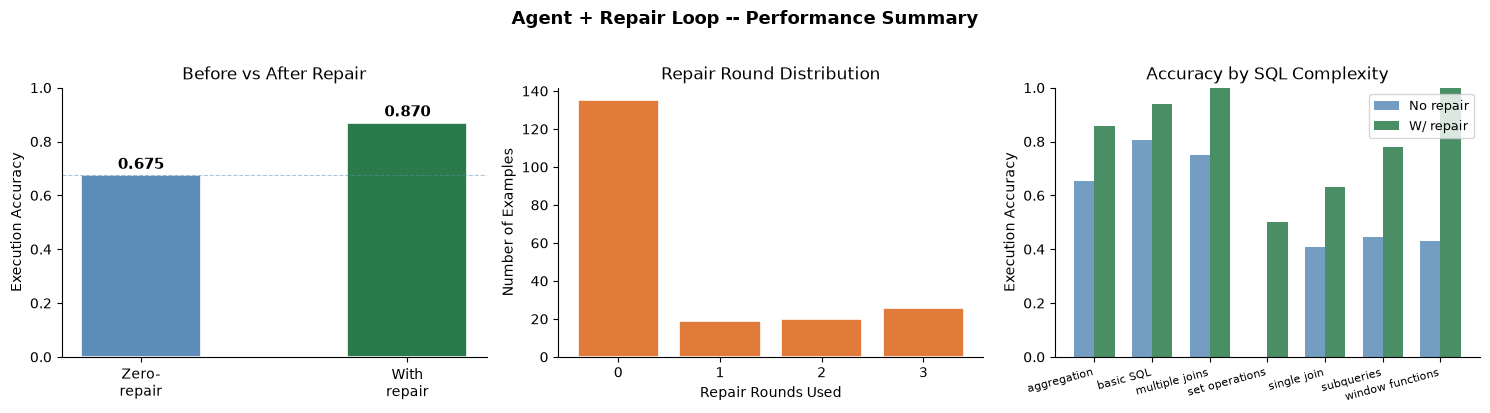

Saved -> agent_repair_summary.png


In [94]:
#matplotlib visualisation of repair impact
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Left: exec accuracy before vs after repair
ax = axes[0]
labels = ['Zero-\nrepair', 'With\nrepair']
vals   = [acc_first, acc_final]
colors = ['#5b8db8', '#2a7a4b']
bars = ax.bar(labels, vals, color=colors, width=0.45, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_ylabel('Execution Accuracy')
ax.set_title('Before vs After Repair', fontsize=12)
ax.spines[['top','right']].set_visible(False)
ax.axhline(acc_first, color='#5b8db8', linestyle='--', linewidth=0.8, alpha=0.5)

# Middle: repair rounds distribution
ax = axes[1]
round_counts = agent_df.repair_rounds.value_counts().sort_index()
ax.bar(round_counts.index.astype(str), round_counts.values,
       color='#e07b39', edgecolor='white', linewidth=1.2)
ax.set_xlabel('Repair Rounds Used')
ax.set_ylabel('Number of Examples')
ax.set_title('Repair Round Distribution', fontsize=12)
ax.spines[['top','right']].set_visible(False)

# Right: accuracy by complexity
ax = axes[2]
comps = comp_table.index.tolist()
x = np.arange(len(comps)); w = 0.35
ax.bar(x - w/2, comp_table.acc_first.values,    w, label='No repair', color='#5b8db8', alpha=0.85)
ax.bar(x + w/2, comp_table.acc_repaired.values, w, label='W/ repair', color='#2a7a4b', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([c.replace('_',' ') for c in comps], rotation=15, ha='right', fontsize=8)
ax.set_ylabel('Execution Accuracy')
ax.set_title('Accuracy by SQL Complexity', fontsize=12)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.set_ylim(0, 1)

plt.suptitle('Agent + Repair Loop -- Performance Summary', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('agent_repair_summary.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved -> agent_repair_summary.png')

### 3.10 Failure Analysis

Inspect examples still wrong after all repair rounds and categorise them.

In [95]:
# failure categorisation

def _lower_or_empty(value):
    return '' if pd.isna(value) else str(value).lower()


def categorise_failure(row):
    err = _lower_or_empty(row['error'])
    pred = _lower_or_empty(row['pred'])
    if 'no such table' in err:
        return 'wrong_table_name'
    if 'no such column' in err:
        return 'wrong_column_name'
    if 'syntax error' in err:
        return 'syntax_error'
    if 'ambiguous' in err:
        return 'ambiguous_column'
    if err:
        return 'other_sql_error'
    if not row['correct']:
        if 'join' in pred:
            return 'wrong_join'
        if 'group by' in pred:
            return 'wrong_aggregation'
        return 'wrong_result'
    return 'correct'


failures = agent_df[~agent_df.correct].copy()
failures['failure_type'] = failures.apply(categorise_failure, axis=1)

print(f'Failed examples: {len(failures)} / {len(agent_df)}')
print('\nFailure categories:')
display(failures.failure_type.value_counts().rename('count').to_frame())

print('\n=== Sample Failures ===')
for _, row in failures.head(3).iterrows():
    err_val = row['error'] if not pd.isna(row['error']) else 'None'
    print(f"\n  ID        : {row['id']}")
    print(f"  Complexity: {row['complexity']}")
    print(f"  Q         : {str(row['question'])[:80]}")
    print(f"  Gold SQL  : {str(row['gold'])[:80]}")
    print(f"  Pred SQL  : {str(row['pred'])[:80]}")
    print(f'  Error     : {err_val}')
    print(f"  Category  : {row['failure_type']}")

Failed examples: 26 / 200

Failure categories:


,count
failure_type,
wrong_result,9
wrong_aggregation,7
wrong_join,5
wrong_column_name,4
other_sql_error,1



=== Sample Failures ===

  ID        : 3510
  Complexity: set operations
  Q         : What is the total number of mobile and broadband subscribers for each technology
  Gold SQL  : SELECT 'Mobile' AS source, technology, COUNT(*) AS total FROM mobile_subscribers
  Pred SQL  : SELECT technology, SUM(CASE WHEN region = 'North' THEN 1 ELSE 0 END) + SUM(CASE 
  Error     : None
  Category  : wrong_aggregation

  ID        : 4542
  Complexity: single join
  Q         : Find the total volume of timber sold in 2021
  Gold SQL  : SELECT SUM(ts.volume) FROM timber_sales ts INNER JOIN forests f ON ts.forest_id 
  Pred SQL  : SELECT SUM(t.volume) FROM timber_sales t WHERE strftime('%Y', t.year) = '2021';
  Error     : None
  Category  : wrong_result

  ID        : 2740
  Complexity: subqueries
  Q         : How many users have a heart rate over 120 BPM for more than 30 minutes in a work
  Gold SQL  : SELECT COUNT(*) FROM (SELECT UserID, SUM(Duration) FROM WorkoutData WHERE AvgHea
  Pred SQL  : S

### 3.11 * Majority Voting

Generate N independent SQL candidates, execute all, and pick the result
that the majority agrees on (by result hash). Runs only when `MAJORITY_VOTE=True`.

*Source: 4_Structured_Generation_Lab Section 3.2 - majority voting at scale.*

In [96]:
#  majority-vote extension following 4_Structured_Generation_Lab Section 3.2
# FIXED: temperature only passed when do_sample=True; safe_rows guards None
import hashlib

def result_hash(rows):
    if not rows:
        return '__empty__'
    key = str(sorted([tuple(str(v) for v in row) for row in rows]))
    return hashlib.md5(key.encode()).hexdigest()[:12]

def agent_majority(question: str, sql_context: str, n: int = MAJORITY_N):
    examples   = _retrieve(question, sql_context)
    candidates = []
    vote_trace = []
    for i in range(n):
        use_sample = (i > 0)   # first candidate greedy; rest sampled
        msgs = build_messages(question, sql_context, examples=examples, style=PROMPT_STYLE)
        input_ids = llm_tok.apply_chat_template(
            msgs, add_generation_prompt=True, return_tensors='pt'
        ).to(device)
        gen_kwargs = dict(
            max_new_tokens=256, do_sample=use_sample,
            pad_token_id=llm_tok.eos_token_id,
        )
        if use_sample:
            gen_kwargs['temperature'] = 0.7   # FIXED: only set when do_sample=True
        with torch.no_grad():
            out = llm.generate(input_ids, **gen_kwargs)
        raw = llm_tok.decode(out[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()
        sql = re.sub(r'^```[a-z]*\n?', '', raw, flags=re.I).rstrip('` \n').strip()
        rows, err = run_sql(sql_context, sql)
        h = result_hash(rows) if err is None else f'__err_{i}__'
        candidates.append((sql, rows, err, h))
        vote_trace.append(f'[Vote {i+1}/{n}] SQL: {sql[:80]} | hash: {h}')

    hash_counts = {}
    for cand_sql, cand_rows, cand_err, cand_h in candidates:
        hash_counts[cand_h] = hash_counts.get(cand_h, 0) + 1
    best_hash = max(hash_counts, key=hash_counts.__getitem__)
    best_sql, best_rows, best_err, _ = next(
        (c for c in candidates if c[3] == best_hash), candidates[0]
    )
    safe_rows = best_rows or []   # FIXED: guard None
    if best_err:
        best_answer = f'Majority SQL failed: {best_err}'
    elif not safe_rows:
        best_answer = 'Majority result: no rows returned.'
    elif len(safe_rows)==1 and len(safe_rows[0])==1:
        best_answer = f'The answer is: {safe_rows[0][0]}'
    else:
        best_answer = f'Found {len(safe_rows)} row(s). First: {safe_rows[0]}'
    vote_trace.append(
        f'[VOTE RESULT] best hash: {best_hash} '
        f'(votes: {hash_counts[best_hash]}/{n}) | answer: {best_answer}'
    )
    return best_sql, best_answer, vote_trace

if MAJORITY_VOTE:
    print(f'Running majority-vote agent (N={MAJORITY_N}) on first 10 test examples ...')
    mv_rows = []
    for ex in list(test_eval)[:10]:
        t0 = _time.time()
        mv_sql, mv_answer, mv_trace = agent_majority(ex['sql_prompt'], ex['sql_context'])
        elapsed = _time.time() - t0
        pred_r, pred_e = run_sql(ex['sql_context'], mv_sql)
        gold_r, gold_e = run_sql(ex['sql_context'], ex['sql'])
        correct = (
            same_result(pred_r, gold_r)
            if (pred_e is None and gold_e is None
                and pred_r is not None and gold_r is not None)
            else False
        )
        mv_rows.append({'id': ex['id'], 'correct': correct, 'sec': round(elapsed, 2)})
        print(f"  {str(ex['id'])[:12]}  correct={correct}  sec={elapsed:.1f}")
    mv_acc = sum(r['correct'] for r in mv_rows) / len(mv_rows)
    print(f'\nMajority-vote accuracy (N={MAJORITY_N}, 10 examples): {mv_acc:.3f}')
    print('(Compare with agent_df.correct.mean() for the same examples)')
else:
    print('MAJORITY_VOTE=False -- skipped. Set MAJORITY_VOTE=True in cell 3.0 to run.')

MAJORITY_VOTE=False -- skipped. Set MAJORITY_VOTE=True in cell 3.0 to run.


### 3.12 `agent_fn` (Evaluation)


In [ ]:
#thin adapter so evaluate.py can call agent() like generate()
def agent_fn(question: str, sql_context: str) -> str:
    final_sql, _, _ = agent(question, sql_context)
    return final_sql

def agent_fn_no_repair(question: str, sql_context: str) -> str:
    final_sql, _, _ = agent(question, sql_context, max_repairs=0)
    return final_sql

print('Exportable functions:')
print('  agent_fn           -> calls agent(q, ctx, max_repairs=3)')
print('  agent_fn_no_repair -> calls agent(q, ctx, max_repairs=0)')
print()
print('  evaluate(agent_fn, test_ds)            # with repair')
print('  evaluate(agent_fn_no_repair, test_ds)  # ablation: 0 repairs')

Exportable functions:
  agent_fn           -> calls agent(q, ctx, max_repairs=3)
  agent_fn_no_repair -> calls agent(q, ctx, max_repairs=0)

Usage by Person 5:
  evaluate(agent_fn, test_ds)            # with repair
  evaluate(agent_fn_no_repair, test_ds)  # ablation: 0 repairs


### 3.13 Part 3 Runtime Summary

In [ ]:
# runtime and file summary
import os

print('=' * 55)
print('  Part 3 -- Summary')
print('=' * 55)

files = {
    'results/agent_repair.json': 'per-example agent results',
    'agent_repair_summary.png':  'repair impact chart',
}
for path, desc in files.items():
    size = os.path.getsize(path) if os.path.exists(path) else -1
    tag  = f'{size:,} bytes' if size >= 0 else 'NOT FOUND'
    print(f'  {path:<35} {tag}  # {desc}')

print()
print('Key metrics:')
# FIXED: guard with try/except in case cell 3.8 was not yet run
try:
    print(f'  Exec accuracy WITHOUT repair : {acc_first:.3f}')
    print(f'  Exec accuracy WITH repair    : {acc_final:.3f}')
    print(f'  Repair success rate          : {repair_rate:.1%}')
    print(f'  Average repair rounds        : {avg_rounds:.2f}')
except NameError:
    print('Metrics to be checked ')
print()
print('Exports for downstream parts:')
print('  agent()              -> (sql, answer, trace)')
print('  agent_fn(q, ctx)     -> sql')
print('  agent_fn_no_repair() -> sql  [ablation]')

  Part 3 -- Summary
  results/agent_repair.json           188,138 bytes  # per-example agent results
  agent_repair_summary.png            89,847 bytes  # repair impact chart

Key metrics:
  Exec accuracy WITHOUT repair : 0.675
  Exec accuracy WITH repair    : 0.870
  Repair success rate          : 60.0%
  Average repair rounds        : 0.69

Exports for downstream parts:
  agent()              -> (sql, answer, trace)
  agent_fn(q, ctx)     -> sql  [for Person 5]
  agent_fn_no_repair() -> sql  [ablation]


# Part 4: LoRA Fine-tuning and Evaluation

This section adds LoRA model training and direct SQL-generation evaluation to the Part 3 agent notebook. The Part 3 agent code above is unchanged.

### How to run

1. Run the LoRA code-definition cell below.
2. Leave `RUN_LORA_EXPERIMENTS = False` to inspect the saved 5k/10k test results.
3. Set it to `True` to train and evaluate all four model/data-size combinations. This takes time and requires a CUDA GPU. New adapters are saved under `notebook_adapters/`, keeping existing adapter folders untouched.

### 4.1 LoRA model code

Training, prompt construction, generation, and evaluation functions from `finetune.py` are included here so they can be run from this notebook.

In [ ]:
from config import CONFIG, SEED, set_seed
import data
# Part 4: Fine-tuning Qwen2.5-0.5B with LoRA (PEFT).
import os, sys, time, json, re, torch
from collections import defaultdict
from transformers import (AutoTokenizer, AutoModelForCausalLM, Trainer,
                          TrainingArguments, DataCollatorForSeq2Seq, TrainerCallback)
from peft import LoraConfig, get_peft_model, PeftModel
BASE = CONFIG["lora_base"]
ADAPTER = CONFIG["adapter_path"]
MAX_LEN = 512
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]

SQLITE_RULE = ("### Instructions:\nWrite one SQLite SELECT query. Use only SQLite syntax: "
               "strftime() or string comparison for dates, no YEAR(), MONTH(), DATE_FORMAT() "
               "or other MySQL functions. Use only the tables and columns in the schema.\n\n")

def build_prompt(question, schema, style="plain"):
    # Used for BOTH training and generation. 
    # style="sqlite" adds the SQLite-only rule; the style is saved with the adapter.
    head = SQLITE_RULE if style == "sqlite" else ""
    return f"{head}### Schema:\n{schema}\n\n### Question:\n{question}\n\n### SQL:\n"

def prompt_of(adapter):
    """Prompt style an adapter was trained with (prompt_style.txt); 'plain' if missing."""
    p = os.path.join(adapter or "", "prompt_style.txt")
    return open(p).read().strip() if adapter and os.path.exists(p) else "plain"

def _encode(ex, tok, style="plain"):
    p_ids = tok(build_prompt(ex["sql_prompt"], ex["sql_context"], style),
                add_special_tokens=False)["input_ids"]
    a_ids = tok(ex["sql"] + tok.eos_token, add_special_tokens=False)["input_ids"]
    ids = p_ids + a_ids
    return {"input_ids": ids, "attention_mask": [1] * len(ids),
            "labels": [-100] * len(p_ids) + a_ids}      # loss only on the SQL

def get_val(train_ds, start=5000, size=50):
    """Validation examples from the train split, never used for training."""
    return train_ds.shuffle(seed=SEED).select(range(start, start + size))

class TxtLogger(TrainerCallback):
    """Appends every Trainer log (loss, lr, grad_norm, ...) to a txt file as training runs."""
    def __init__(self, path, header=""):
        self.path = path
        with open(path, "a", encoding="utf-8") as f:
            f.write(f"\n=== {time.strftime('%Y-%m-%d %H:%M:%S')} {header}\n")

    def on_log(self, args, state, control, logs=None, **kw):
        with open(self.path, "a", encoding="utf-8") as f:
            f.write(f"step {state.global_step}/{state.max_steps}  {json.dumps(logs)}\n")

def train_lora(train_ds, n=1000, epochs=2, r=16, lr=2e-4,
               targets=TARGETS, adapter=ADAPTER,
               batch_size=4, grad_accum=4, grad_ckpt=False, log_file=None,
               base=BASE, dtype=torch.float32, prompt="plain", max_len=MAX_LEN):
    # batch_size/grad_accum/grad_ckpt: lower memory on small GPUs (8 GB) without
    # changing the effective batch size (batch_size * grad_accum).
    # log_file: if given, training logs are written there live (TxtLogger).
    # base/dtype: e.g. base=CONFIG["llm"] (Coder-1.5B) with dtype=torch.bfloat16 to fit 8 GB.
    set_seed()
    tok = AutoTokenizer.from_pretrained(base)
    ds = train_ds.shuffle(seed=SEED).select(range(n))
    ds = ds.map(lambda ex: _encode(ex, tok, prompt), remove_columns=ds.column_names)
    before = len(ds)
    ds = ds.filter(lambda ex: len(ex["input_ids"]) <= max_len)
    print(f"kept {len(ds)} of {before} examples (rest longer than {max_len} tokens)")

    model = AutoModelForCausalLM.from_pretrained(base, torch_dtype=dtype).to("cuda")
    cfg = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05,
                     target_modules=targets, task_type="CAUSAL_LM")
    model = get_peft_model(model, cfg)
    model.print_trainable_parameters()

    bf16 = torch.cuda.is_bf16_supported()
    args = TrainingArguments(
        output_dir="lora_out", per_device_train_batch_size=batch_size,
        gradient_accumulation_steps=grad_accum, learning_rate=lr,
        gradient_checkpointing=grad_ckpt,
        gradient_checkpointing_kwargs={"use_reentrant": False} if grad_ckpt else None,
        num_train_epochs=epochs, logging_steps=5, save_strategy="no",
        bf16=bf16, fp16=not bf16, report_to="none", seed=SEED)
    callbacks = [TxtLogger(log_file, f"n={n} r={r} lr={lr} epochs={epochs} "
                           f"targets={targets} batch={batch_size}x{grad_accum} "
                           f"max_len={max_len} base={base} adapter={adapter} "
                           f"prompt={prompt}")] if log_file else []
    Trainer(model=model, args=args, train_dataset=ds, callbacks=callbacks,
            data_collator=DataCollatorForSeq2Seq(tok, padding=True,
                                                 label_pad_token_id=-100)).train()
    model.save_pretrained(adapter)
    tok.save_pretrained(adapter)
    with open(os.path.join(adapter, "prompt_style.txt"), "w") as f:
        f.write(prompt)
    print("saved to", adapter)

def base_of(adapter):
    """Base model an adapter was trained on (from adapter_config.json); BASE if unknown."""
    cfg = os.path.join(adapter or "", "adapter_config.json")
    if adapter and os.path.exists(cfg):
        with open(cfg) as f:
            return json.load(f).get("base_model_name_or_path", BASE)
    return BASE

_cache = {}
def _load(adapter=None, base=None):
    base = base or base_of(adapter)
    key = (base, adapter or "base")
    if key not in _cache:
        tok = AutoTokenizer.from_pretrained(base)
        tok.padding_side = "left"
        model = AutoModelForCausalLM.from_pretrained(base, torch_dtype=torch.float16).to("cuda")
        if adapter:                       # adapter=None -> plain base model ("before")
            model = PeftModel.from_pretrained(model, adapter)
        _cache[key] = (tok, model.eval())
    return _cache[key]

def generate_lora(question, schema, adapter=ADAPTER, max_new_tokens=256, stop=(";",),
                  clean=True, base=None, prompt=None):
    """Same inputs/output as rag.generate(question, schema): returns one SQL string.
    stop=(';',) ends generation after the first statement (much faster);
    clean=True strips ```sql fences / extra text. Pass stop=None, clean=False for raw output.
    The base model and prompt style are read from the adapter; base=/prompt= override them."""
    tok, model = _load(adapter, base)
    style = prompt or prompt_of(adapter)
    inputs = tok(build_prompt(question, schema, style), return_tensors="pt").to("cuda")
    extra = {"stop_strings": list(stop), "tokenizer": tok} if stop else {}
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id, **extra)
    text = tok.decode(out[0][inputs["input_ids"].shape[1]:],
                      skip_special_tokens=True).strip()
    return clean_sql(text) if clean else text

def setup_lora(train_ds=None, n=None, adapter=ADAPTER, **kw):
    """Notebook entry point. config.TRAIN=True -> train and save the adapter;
    TRAIN=False -> just load the saved adapter (download lora_adapter/ from Drive first)."""
    import os
    from config import TRAIN
    if TRAIN:
        assert train_ds is not None, "TRAIN=True needs train_ds"
        train_lora(train_ds, n=n or CONFIG["lora_train_size"], adapter=adapter, **kw)
    elif not os.path.exists(os.path.join(adapter, "adapter_model.safetensors")):
        raise FileNotFoundError(f"{adapter} not found: download the adapter from Drive "
                                "into the repo folder, or set TRAIN=True in config.py")
    _load(adapter)
    print("LoRA adapter ready:", adapter)
    return adapter

def eval_lora(ds, adapter=ADAPTER):
    """adapter=None evaluates the base model without LoRA (the 'before' number)."""
    from data import run_sql, same_result          
    ok = 0
    for ex in ds:
        pred = generate_lora(ex["sql_prompt"], ex["sql_context"], adapter)
        p_rows, err = run_sql(ex["sql_context"], pred)
        g_rows, _ = run_sql(ex["sql_context"], ex["sql"])
        ok += (err is None) and same_result(p_rows, g_rows)
    return ok / len(ds)

def _norm_sql(s):
    return re.sub(r"\s+", " ", s.strip().rstrip(";")).lower()

def clean_sql(text):
    """Pull the first SQL statement out of model output: drops ```sql fences,
    trailing '### ...' sections and anything after the first ';'."""
    m = re.search(r"```(?:sql)?\s*(.*?)(```|$)", text, re.S | re.I)
    if m:
        text = m.group(1)
    text = text.split("###")[0]
    if ";" in text:
        text = text[:text.index(";") + 1]
    return text.strip()

def eval_lora_detailed(ds, adapter=ADAPTER, out_txt=None, name=None, base=None, prompt=None,
                       out_json=None):
    """Test-set metrics: execution accuracy, exact match, valid-SQL rate,
    accuracy by sql_complexity and latency. Writes one line per example to
    out_txt as it goes, then a summary. adapter=None -> base model.
    out_json: if given, the full predicted SQL per example is saved there (query_match.py).
    Same post-processing (stop at ';' + clean_sql) for base and LoRA, so it's fair."""
    from data import run_sql, same_result
    name = name or (adapter or "base")
    f = open(out_txt, "a", encoding="utf-8") if out_txt else None
    def w(line):
        print(line, flush=True)
        if f:
            f.write(line + "\n"); f.flush()

    w(f"\n=== {time.strftime('%Y-%m-%d %H:%M:%S')} eval {name} on {len(ds)} examples")
    n_exec = n_em = n_valid = n_gold_ok = 0
    by_cx = defaultdict(lambda: [0, 0])          # complexity -> [correct, total]
    secs, records = [], []
    for i, ex in enumerate(ds):
        t0 = time.time()
        pred = generate_lora(ex["sql_prompt"], ex["sql_context"], adapter, base=base,
                             prompt=prompt)
        secs.append(time.time() - t0)
        p_rows, err = run_sql(ex["sql_context"], pred)
        g_rows, g_err = run_sql(ex["sql_context"], ex["sql"])
        exec_ok = err is None and g_err is None and same_result(p_rows, g_rows)
        em = _norm_sql(pred) == _norm_sql(ex["sql"])
        n_exec += exec_ok; n_em += em; n_valid += err is None; n_gold_ok += g_err is None
        cx = ex.get("sql_complexity", "unknown")
        by_cx[cx][0] += exec_ok; by_cx[cx][1] += 1
        records.append({"id": ex["id"], "complexity": cx, "question": ex["sql_prompt"],
                        "pred": pred, "gold": ex["sql"], "error": err,
                        "correct": bool(exec_ok)})
        w(f"[{i+1}/{len(ds)}] exec={int(exec_ok)} em={int(em)} {secs[-1]:.1f}s "
          f"running_acc={n_exec/(i+1):.3f} cx={cx}"
          + (f" err={err[:80]}" if err else "") + f" | pred: {pred[:150]!r}")

    n = len(ds)
    m = {"system": name, "n_eval": n,
         "exec_acc": round(n_exec / n, 4), "exact_match": round(n_em / n, 4),
         "valid_sql": round(n_valid / n, 4), "gold_runs": round(n_gold_ok / n, 4),
         "sec_per_example": round(sum(secs) / n, 2),
         "by_complexity": {k: {"acc": round(c / t, 4), "n": t}
                           for k, (c, t) in sorted(by_cx.items())}}
    w("SUMMARY " + json.dumps(m, indent=2))
    if f:
        f.close()
    if out_json:
        with open(out_json, "w", encoding="utf-8") as jf:
            json.dump(records, jf, indent=1)
    return m


### 4.2 Train and evaluate 0.5B/1.5B models with 5k/10k examples

In [ ]:
import gc
from pathlib import Path
RESULTS = Path("results")
RUN_LORA_EXPERIMENTS = False
LORA_EXPERIMENTS = [
    {"size": "0.5B", "base": CONFIG["lora_base"], "dtype": torch.float32, "n": 5000, "name": "0_5b_5k"},
    {"size": "0.5B", "base": CONFIG["lora_base"], "dtype": torch.float32, "n": 10000, "name": "0_5b_10k"},
    {"size": "1.5B", "base": CONFIG["llm"], "dtype": torch.bfloat16, "n": 5000, "name": "1_5b_5k"},
    {"size": "1.5B", "base": CONFIG["llm"], "dtype": torch.bfloat16, "n": 10000, "name": "1_5b_10k"},
]

if RUN_LORA_EXPERIMENTS:
    RESULTS.mkdir(exist_ok=True)
    train_ds, _, test_ds = data.get_splits(quick_run=False)

    for exp in LORA_EXPERIMENTS:
        adapter_path = Path("notebook_adapters") / f"lora_{exp['name']}"
        if adapter_path.exists() and any(adapter_path.iterdir()):
            raise FileExistsError(f"Adapter already exists; choose a new output folder: {adapter_path}")

        print(f"\nTraining {exp['size']} using {exp['n']:,} examples")
        train_lora(
            train_ds, n=exp["n"], epochs=1, r=16, lr=2e-4,
            adapter=str(adapter_path), batch_size=2, grad_accum=8,
            grad_ckpt=True, log_file=RESULTS / "notebook_lora_train_log.txt",
            base=exp["base"], dtype=exp["dtype"], max_len=512,
        )

        gc.collect()
        torch.cuda.empty_cache()
        metrics = eval_lora_detailed(
            test_ds, adapter=str(adapter_path),
            name=f"LoRA {exp['size']} ({exp['n']:,} examples)",
            base=exp["base"],
            out_txt=RESULTS / f"notebook_lora_{exp['name']}_test.txt",
            out_json=RESULTS / f"notebook_lora_{exp['name']}_predictions.json",
        )
        metrics_file = RESULTS / f"notebook_lora_{exp['name']}_metrics.json"
        metrics_file.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
else:
    print("LoRA experiments skipped. Set RUN_LORA_EXPERIMENTS = True to train and evaluate.")

LoRA experiments skipped. Set RUN_LORA_EXPERIMENTS = True to train and evaluate.


### 4.3 Compare the saved 5k/10k test metrics

This cell reads the four existing evaluation results; it does not load models or retrain.

In [3]:
from pathlib import Path
import json

RESULTS = Path("results")
RESULT_FILES = [
    ("0.5B", 5000, "lora_adapter_5k"),
    ("0.5B", 10000, "lora_adapter_10k"),
    ("1.5B", 5000, "lora_adapter_coder5k"),
    ("1.5B", 10000, "lora_adapter_coder10k"),
]

comparison = []
for model_size, train_size, adapter_name in RESULT_FILES:
    metrics_path = RESULTS / f"lora_metrics_{adapter_name}_test.json"
    if not metrics_path.exists():
        print(f"Saved metrics not found: {metrics_path}")
        continue
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    comparison.append({
        "Model": model_size,
        "Train examples": train_size,
        "Test examples": metrics["n_eval"],
        "Execution accuracy": metrics["exec_acc"],
        "Exact match": metrics["exact_match"],
        "Valid SQL": metrics["valid_sql"],
    })

for result in comparison:
    print(result)

{'Model': '0.5B', 'Train examples': 5000, 'Test examples': 200, 'Execution accuracy': 0.605, 'Exact match': 0.285, 'Valid SQL': 0.955}
{'Model': '0.5B', 'Train examples': 10000, 'Test examples': 200, 'Execution accuracy': 0.655, 'Exact match': 0.31, 'Valid SQL': 0.935}
{'Model': '1.5B', 'Train examples': 5000, 'Test examples': 200, 'Execution accuracy': 0.69, 'Exact match': 0.33, 'Valid SQL': 0.975}
{'Model': '1.5B', 'Train examples': 10000, 'Test examples': 200, 'Execution accuracy': 0.715, 'Exact match': 0.36, 'Valid SQL': 0.97}


### 4.4 Results by SQL complexity

This table and chart compare direct LoRA generation accuracy for each complexity type. `n` is the number of test examples in that category. These are direct-generation metrics, so there are no repair-round columns here; repair statistics are reported in Part 3.

model,n,0.5B ? 10k,0.5B ? 5k,1.5B ? 10k,1.5B ? 5k
complexity,,,,,
aggregation,49,57.1%,49.0%,61.2%,61.2%
basic SQL,102,82.3%,78.4%,87.2%,83.3%
multiple_joins,4,25.0%,50.0%,100.0%,100.0%
set operations,2,0.0%,0.0%,0.0%,0.0%
single join,27,51.8%,48.1%,63.0%,55.6%
subqueries,9,44.4%,22.2%,22.2%,33.3%
window functions,7,0.0%,0.0%,14.3%,14.3%


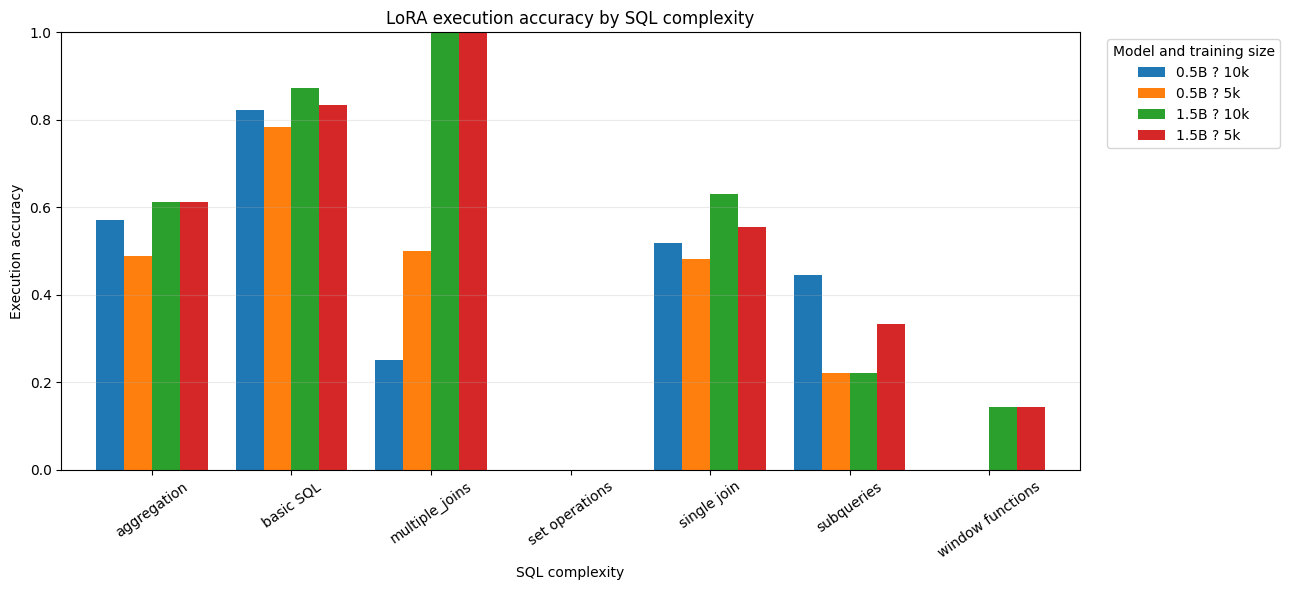

In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

results_dir = Path("results")
models_to_show = [
    ("0.5B ? 5k", "lora_adapter_5k"),
    ("0.5B ? 10k", "lora_adapter_10k"),
    ("1.5B ? 5k", "lora_adapter_coder5k"),
    ("1.5B ? 10k", "lora_adapter_coder10k"),
]

accuracy_rows = []
counts = {}
for model_name, adapter_name in models_to_show:
    metrics_file = results_dir / f"lora_metrics_{adapter_name}_test.json"
    if not metrics_file.exists():
        print(f"Metrics not found: {metrics_file}. Run the LoRA evaluation first.")
        continue

    metrics = json.loads(metrics_file.read_text(encoding="utf-8"))
    for complexity, values in metrics["by_complexity"].items():
        counts[complexity] = values["n"]
        accuracy_rows.append({
            "complexity": complexity,
            "model": model_name,
            "execution_accuracy": values["acc"],
        })

if accuracy_rows:
    accuracy = pd.DataFrame(accuracy_rows)
    accuracy_table = accuracy.pivot(
        index="complexity", columns="model", values="execution_accuracy"
    )
    accuracy_table.insert(0, "n", pd.Series(counts))
    accuracy_table = accuracy_table.rename_axis("complexity")
    display(accuracy_table.style.format({column: "{:.1%}" for column in accuracy_table.columns if column != "n"}))

    accuracy_plot = accuracy_table.drop(columns="n").plot(
        kind="bar", figsize=(13, 6), ylim=(0, 1), width=0.8
    )
    accuracy_plot.set_title("LoRA execution accuracy by SQL complexity")
    accuracy_plot.set_xlabel("SQL complexity")
    accuracy_plot.set_ylabel("Execution accuracy")
    accuracy_plot.legend(title="Model and training size", bbox_to_anchor=(1.02, 1), loc="upper left")
    accuracy_plot.tick_params(axis="x", rotation=35)
    accuracy_plot.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No saved per-complexity metrics to display yet.")

/home/aidslab/GenAI/.venv/bin/python


# Part 5: Final Evaluation, Ablations, and Error Analysis

This section evaluates the saved systems on the configured fixed test IDs, reports execution accuracy and exact match, measures repair behavior from saved traces, compares the LoRA runs, and produces subgroup charts and a ten-case failure analysis. Every comparison records its sample size; systems are never treated as paired when their IDs differ.

### 5.1 Evaluation Protocol

The primary baseline, few-shot RAG, and repair-agent comparison uses only test IDs present in every selected per-example artifact. SQL is re-executed against each example's SQLite context, and execution accuracy is based on result-set equality. Exact SQL match is secondary. Dataset metadata supplies the canonical domain and complexity labels. LoRA metric summaries are reported separately unless per-example predictions are available for the same cohort.

In [23]:
from pathlib import Path
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import data

EVAL_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "test_ids.json").exists() and (path / "results").exists()),
    Path.cwd(),
)
EVAL_RESULTS = EVAL_ROOT / "results"
EVAL_LORA = EVAL_ROOT / "lora_experiment_results"

with (EVAL_ROOT / "test_ids.json").open(encoding="utf-8") as file:
    EVAL_TEST_IDS = {int(example_id) for example_id in json.load(file)}

EVAL_DATASET = data.load_data()
EVAL_ROWS_BY_ID = {}
for split_name in EVAL_DATASET:
    for example in EVAL_DATASET[split_name]:
        example_id = int(example["id"])
        if example_id in EVAL_TEST_IDS:
            EVAL_ROWS_BY_ID[example_id] = example

EVAL_MISSING_DATA_IDS = EVAL_TEST_IDS - set(EVAL_ROWS_BY_ID)
if EVAL_MISSING_DATA_IDS:
    raise ValueError(f"Test IDs missing from downloaded dataset: {sorted(EVAL_MISSING_DATA_IDS)[:10]}")

print(f"Configured fixed test IDs: {len(EVAL_TEST_IDS)}")
print(f"Dataset rows resolved: {len(EVAL_ROWS_BY_ID)}")

Configured fixed test IDs: 200
Dataset rows resolved: 200


### 5.2 Fixed-Cohort Baseline and Full-System Results

The selected systems include zero-shot, retrieved few-shot (BM25 k=3), an additional retrieval baseline when saved, and the repair agent. The intersection is restricted to `test_ids.json`; any artifact coverage loss is printed before metrics are calculated.

In [24]:
EVAL_ARTIFACT_PATHS = {
    "Zero-shot (k=0)": EVAL_RESULTS / "test_zero_shot.json",
    "BM25 few-shot (k=3)": EVAL_RESULTS / "test_bm25_k3.json",
    "Dense few-shot (k=5)": EVAL_RESULTS / "test_dense_k5.json",
    "Random few-shot (k=3)": EVAL_RESULTS / "test_random_k3.json",
    "Agent with repair": EVAL_RESULTS / "agent_repair.json",
}
EVAL_ARTIFACTS = {}
for system_name, artifact_path in EVAL_ARTIFACT_PATHS.items():
    if artifact_path.exists():
        with artifact_path.open(encoding="utf-8") as file:
            records = json.load(file)
        EVAL_ARTIFACTS[system_name] = {int(record["id"]): record for record in records}
    else:
        print(f"Artifact unavailable: {artifact_path.relative_to(EVAL_ROOT)}")

EVAL_COMMON_IDS = set(EVAL_TEST_IDS)
for records_by_id in EVAL_ARTIFACTS.values():
    EVAL_COMMON_IDS &= set(records_by_id)
if not EVAL_COMMON_IDS:
    raise ValueError("No common test IDs found across the available system artifacts.")

print(f"Common fixed-test cohort: {len(EVAL_COMMON_IDS)} / {len(EVAL_TEST_IDS)}")
for system_name, records_by_id in EVAL_ARTIFACTS.items():
    covered_ids = set(records_by_id) & EVAL_TEST_IDS
    print(f"  {system_name:<24} {len(covered_ids):>3} IDs; missing {len(EVAL_TEST_IDS - covered_ids)}")


def _eval_normalize_sql(sql):
    return re.sub(r"\s+", " ", (sql or "").strip().rstrip(";")).casefold()


_EVAL_SQL_CACHE = {}


def _eval_run_sql(example_id, sql):
    cache_key = (int(example_id), sql or "")
    if cache_key not in _EVAL_SQL_CACHE:
        example = EVAL_ROWS_BY_ID[int(example_id)]
        _EVAL_SQL_CACHE[cache_key] = data.run_sql(example.get("sql_context", ""), sql or "")
    return _EVAL_SQL_CACHE[cache_key]


EVAL_ROWS = []
for system_name, records_by_id in EVAL_ARTIFACTS.items():
    for example_id in sorted(EVAL_COMMON_IDS):
        record = records_by_id[example_id]
        example = EVAL_ROWS_BY_ID[example_id]
        prediction = record.get("pred", "") or ""
        gold_sql = example["sql"]
        predicted_rows, predicted_error = _eval_run_sql(example_id, prediction)
        gold_rows, gold_error = _eval_run_sql(example_id, gold_sql)
        EVAL_ROWS.append({
            "system": system_name,
            "id": example_id,
            "domain": example.get("domain", "unknown"),
            "complexity": example.get("sql_complexity", "unknown"),
            "question": example.get("sql_prompt", record.get("question", "")),
            "pred": prediction,
            "gold": gold_sql,
            "correct": bool(gold_error is None and data.same_result(predicted_rows, gold_rows)),
            "exact_match": _eval_normalize_sql(prediction) == _eval_normalize_sql(gold_sql),
            "valid_sql": predicted_error is None,
            "pred_error": predicted_error,
            "gold_error": gold_error,
            "sec": record.get("sec", np.nan),
        })

EVAL_DF = pd.DataFrame(EVAL_ROWS)
EVAL_SYSTEM_TABLE = (
    EVAL_DF.groupby("system", sort=False)
    .agg(
        n=("id", "count"),
        execution_accuracy=("correct", "mean"),
        exact_match=("exact_match", "mean"),
        valid_sql=("valid_sql", "mean"),
        gold_executable=("gold_error", lambda values: values.isna().mean()),
        mean_generation_seconds=("sec", "mean"),
    )
    .reset_index()
)
EVAL_SYSTEM_TABLE.to_csv(EVAL_RESULTS / "fixed_cohort_results.csv", index=False)
display(EVAL_SYSTEM_TABLE.style.format({
    "execution_accuracy": "{:.1%}",
    "exact_match": "{:.1%}",
    "valid_sql": "{:.1%}",
    "gold_executable": "{:.1%}",
    "mean_generation_seconds": "{:.2f}",
}))
print(f"Saved: {EVAL_RESULTS / 'fixed_cohort_results.csv'}")

Common fixed-test cohort: 154 / 200
  Zero-shot (k=0)          200 IDs; missing 0
  BM25 few-shot (k=3)      200 IDs; missing 0
  Dense few-shot (k=5)     154 IDs; missing 46
  Random few-shot (k=3)    200 IDs; missing 0
  Agent with repair        154 IDs; missing 46


,system,n,execution_accuracy,exact_match,valid_sql,gold_executable,mean_generation_seconds
0,Zero-shot (k=0),154,64.9%,35.1%,94.2%,100.0%,0.19
1,BM25 few-shot (k=3),154,73.4%,44.8%,94.8%,100.0%,0.31
2,Dense few-shot (k=5),154,69.5%,41.6%,89.6%,100.0%,0.30
3,Random few-shot (k=3),154,64.9%,35.7%,94.2%,100.0%,0.24
4,Agent with repair,154,87.7%,59.7%,97.4%,100.0%,0.53


Saved: /home/aidslab/GenAI/p05-text-to-sql-analyst/results/fixed_cohort_results.csv


### 5.3 Results by Complexity and Domain

These breakdowns use the same common fixed-test cohort as the primary table. Small domain groups remain visible in the CSV; the chart focuses on the most represented domains for readability.

Execution accuracy by SQL complexity:


system,Agent with repair,BM25 few-shot (k=3),Dense few-shot (k=5),Random few-shot (k=3),Zero-shot (k=0)
complexity,,,,,
aggregation,100.0%,62.5%,75.0%,62.5%,50.0%
basic SQL,94.1%,79.4%,80.4%,78.4%,78.4%
multiple_joins,100.0%,100.0%,75.0%,75.0%,75.0%
set operations,50.0%,0.0%,0.0%,0.0%,0.0%
single join,63.0%,66.7%,40.7%,37.0%,37.0%
subqueries,77.8%,44.4%,44.4%,22.2%,33.3%
window functions,100.0%,50.0%,50.0%,0.0%,0.0%


Execution accuracy by domain (complete table saved to CSV):


,domain,system,n,execution_accuracy,exact_match
315,aerospace,Agent with repair,2,100.0%,0.0%
81,aerospace,BM25 few-shot (k=3),2,100.0%,0.0%
159,aerospace,Dense few-shot (k=5),2,100.0%,0.0%
237,aerospace,Random few-shot (k=3),2,100.0%,0.0%
3,aerospace,Zero-shot (k=0),2,100.0%,0.0%
343,agriculture,Agent with repair,2,100.0%,50.0%
109,agriculture,BM25 few-shot (k=3),2,50.0%,0.0%
187,agriculture,Dense few-shot (k=5),2,50.0%,0.0%
265,agriculture,Random few-shot (k=3),2,100.0%,0.0%
31,agriculture,Zero-shot (k=0),2,100.0%,0.0%


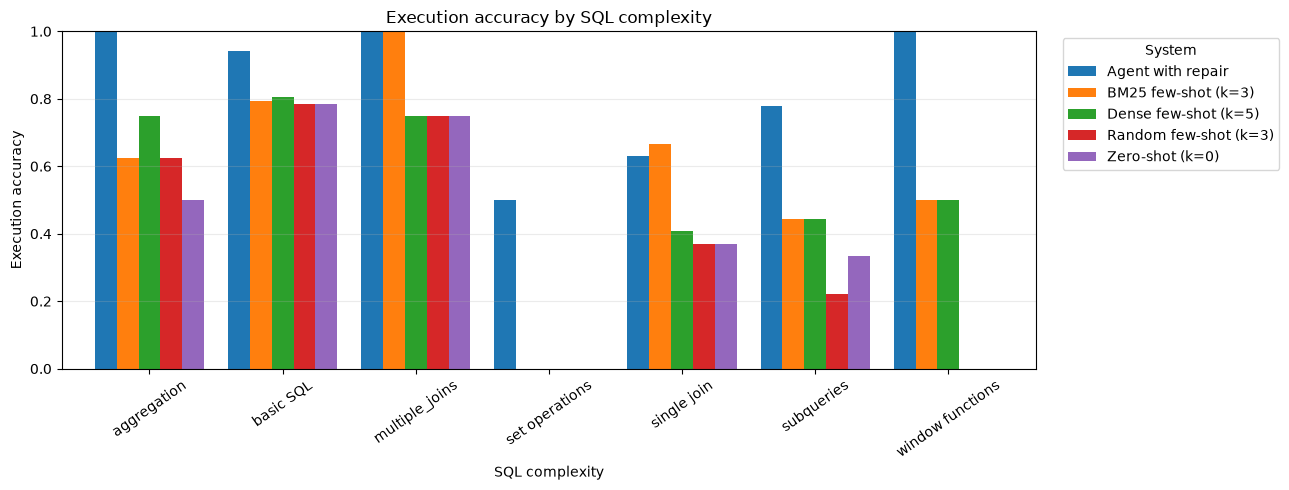

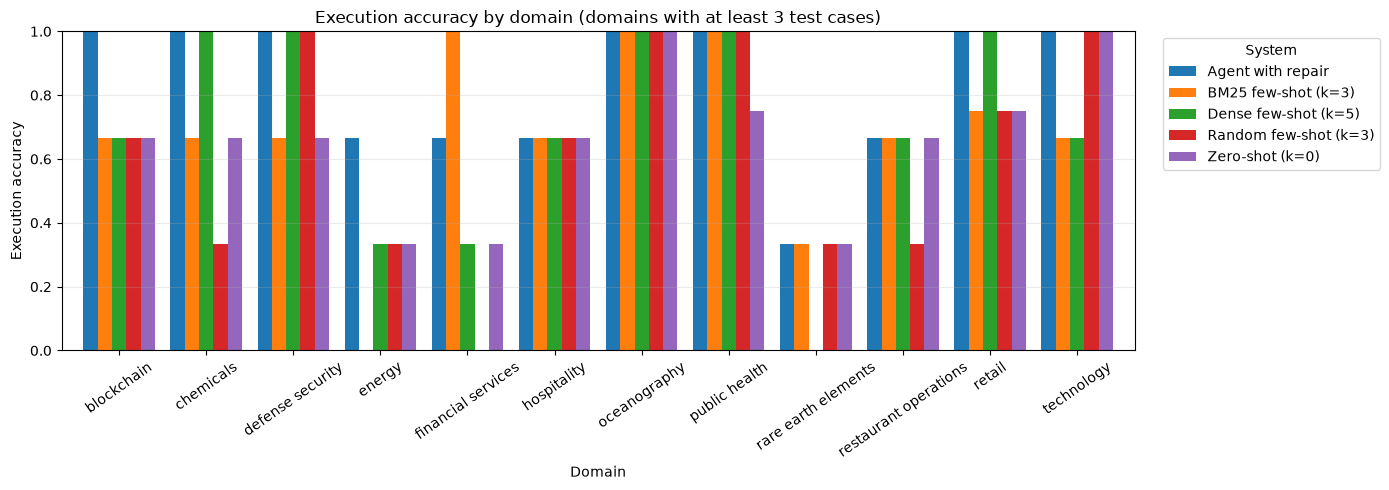

Saved complexity/domain tables and charts.


In [11]:
EVAL_BY_COMPLEXITY = (
    EVAL_DF.groupby(["complexity", "system"], sort=False)
    .agg(n=("id", "count"), execution_accuracy=("correct", "mean"), exact_match=("exact_match", "mean"))
    .reset_index()
)
EVAL_BY_DOMAIN = (
    EVAL_DF.groupby(["domain", "system"], sort=False)
    .agg(n=("id", "count"), execution_accuracy=("correct", "mean"), exact_match=("exact_match", "mean"))
    .reset_index()
)
EVAL_BY_COMPLEXITY.to_csv(EVAL_RESULTS / "accuracy_by_complexity.csv", index=False)
EVAL_BY_DOMAIN.to_csv(EVAL_RESULTS / "accuracy_by_domain.csv", index=False)

print("Execution accuracy by SQL complexity:")
display(EVAL_BY_COMPLEXITY.pivot(index="complexity", columns="system", values="execution_accuracy").style.format("{:.1%}"))
print("Execution accuracy by domain (complete table saved to CSV):")
display(EVAL_BY_DOMAIN.sort_values(["domain", "system"]).head(20).style.format({"execution_accuracy": "{:.1%}", "exact_match": "{:.1%}"}))

complexity_plot = EVAL_BY_COMPLEXITY.pivot(index="complexity", columns="system", values="execution_accuracy").plot(
    kind="bar", figsize=(13, 5), ylim=(0, 1), width=0.82,
)
complexity_plot.set_title("Execution accuracy by SQL complexity")
complexity_plot.set_xlabel("SQL complexity")
complexity_plot.set_ylabel("Execution accuracy")
complexity_plot.tick_params(axis="x", rotation=35)
complexity_plot.grid(axis="y", alpha=0.25)
complexity_plot.legend(title="System", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(EVAL_ROOT / "accuracy_by_complexity.png", dpi=140, bbox_inches="tight")
plt.show()

_domain_counts = EVAL_DF[["id", "domain"]].drop_duplicates()["domain"].value_counts()
_top_domains = _domain_counts[_domain_counts >= 3].head(12).index
_domain_plot_data = EVAL_BY_DOMAIN[EVAL_BY_DOMAIN["domain"].isin(_top_domains)]
domain_plot = _domain_plot_data.pivot(index="domain", columns="system", values="execution_accuracy").plot(
    kind="bar", figsize=(14, 5), ylim=(0, 1), width=0.82,
)
domain_plot.set_title("Execution accuracy by domain (domains with at least 3 test cases)")
domain_plot.set_xlabel("Domain")
domain_plot.set_ylabel("Execution accuracy")
domain_plot.tick_params(axis="x", rotation=35)
domain_plot.grid(axis="y", alpha=0.25)
domain_plot.legend(title="System", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(EVAL_ROOT / "accuracy_by_domain.png", dpi=140, bbox_inches="tight")
plt.show()
print("Saved complexity/domain tables and charts.")

### 5.4 Execution-Guided Repair Ablation

Round 0 uses the saved `first_correct` score; the completed run uses the final SQL re-executed above. The saved trace is truncated during some multi-round attempts, so round 1 is reported only for examples whose run stopped within one repair. Its smaller `n` is shown explicitly and must not be read as a full-cohort estimate.

,round_limit,n,execution_accuracy,initial_accuracy,avg_rounds_used,repair_success_rate
0,0,154,69.5%,69.5%,0.00,0.0%
1,1,119,100.0%,89.9%,0.10,100.0%
2,3,154,87.7%,69.5%,0.66,59.6%


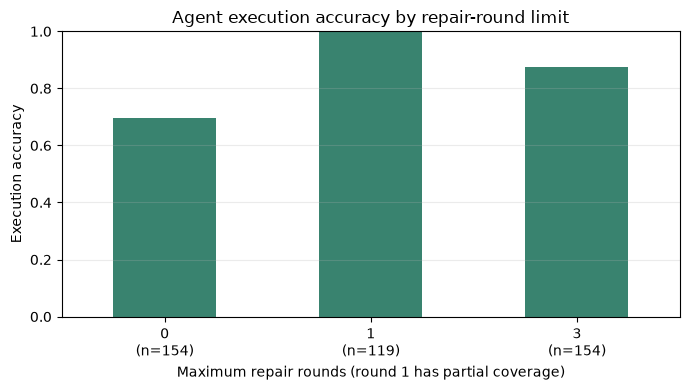

Round 1 is evaluable for 119 cases; multi-round intermediate SQL is truncated in the saved traces.
Repair-round results saved to /home/aidslab/GenAI/p05-text-to-sql-analyst/results/repair_round_ablation.csv


In [12]:
EVAL_REPAIR_ROWS = []
EVAL_AGENT_BY_ROUND = {}
EVAL_AGENT_FINAL = EVAL_DF.loc[EVAL_DF["system"] == "Agent with repair"].set_index("id")

for example_id in sorted(EVAL_COMMON_IDS):
    if example_id not in EVAL_ARTIFACTS.get("Agent with repair", {}):
        continue
    agent_record = EVAL_ARTIFACTS["Agent with repair"][example_id]
    initial_success = bool(agent_record.get("first_correct", False))
    final_success = bool(EVAL_AGENT_FINAL.loc[example_id, "correct"])
    actual_rounds = int(agent_record.get("repair_rounds", 0) or 0)
    round_outcomes = {0: (initial_success, True), 3: (final_success, True)}
    round_outcomes[1] = (
        (initial_success if actual_rounds == 0 else final_success, True)
        if actual_rounds <= 1
        else (False, False)
    )
    EVAL_AGENT_BY_ROUND[example_id] = round_outcomes

    for round_limit in (0, 1, 3):
        correct, evaluable = round_outcomes[round_limit]
        if evaluable:
            EVAL_REPAIR_ROWS.append({
                "id": example_id,
                "round_limit": round_limit,
                "correct": correct,
                "initial_correct": initial_success,
                "repair_success": (not initial_success and correct),
                "rounds_used": min(actual_rounds, round_limit),
            })

EVAL_REPAIR_CASES = pd.DataFrame(EVAL_REPAIR_ROWS)
EVAL_REPAIR_TABLE = (
    EVAL_REPAIR_CASES.groupby("round_limit")
    .agg(
        n=("id", "nunique"),
        execution_accuracy=("correct", "mean"),
        initial_accuracy=("initial_correct", "mean"),
        avg_rounds_used=("rounds_used", "mean"),
    )
    .reset_index()
)
for row_index, row in EVAL_REPAIR_TABLE.iterrows():
    limit = int(row["round_limit"])
    known_cases = EVAL_REPAIR_CASES[EVAL_REPAIR_CASES["round_limit"] == limit]
    initial_failures = int((~known_cases["initial_correct"]).sum())
    fixed_count = int(known_cases["repair_success"].sum())
    EVAL_REPAIR_TABLE.loc[row_index, "repair_success_rate"] = (
        fixed_count / initial_failures if initial_failures else np.nan
    )

EVAL_REPAIR_TABLE.to_csv(EVAL_RESULTS / "repair_round_ablation.csv", index=False)
display(EVAL_REPAIR_TABLE.style.format({
    "execution_accuracy": "{:.1%}",
    "initial_accuracy": "{:.1%}",
    "repair_success_rate": "{:.1%}",
    "avg_rounds_used": "{:.2f}",
}))

repair_plot = EVAL_REPAIR_TABLE.plot(
    x="round_limit", y="execution_accuracy", kind="bar", legend=False,
    figsize=(7, 4), ylim=(0, 1), color="#39836f",
)
repair_plot.set_title("Agent execution accuracy by repair-round limit")
repair_plot.set_xlabel("Maximum repair rounds (round 1 has partial coverage)")
repair_plot.set_ylabel("Execution accuracy")
repair_plot.set_xticklabels([
    f"{int(row.round_limit)}\n(n={int(row.n)})" for row in EVAL_REPAIR_TABLE.itertuples()
], rotation=0)
repair_plot.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(EVAL_ROOT / "repair_round_ablation.png", dpi=140, bbox_inches="tight")
plt.show()
print(f"Round 1 is evaluable for {int(EVAL_REPAIR_TABLE.loc[EVAL_REPAIR_TABLE['round_limit'] == 1, 'n'].iloc[0])} cases; multi-round intermediate SQL is truncated in the saved traces.")
print(f"Repair-round results saved to {EVAL_RESULTS / 'repair_round_ablation.csv'}")

### 5.5 LoRA vs Few-Shot Model Comparison

The model comparison uses the full configured 200-ID test split. Few-shot 1.5B and zero-shot baselines are re-evaluated from per-example predictions. LoRA 5k results use saved metric summaries because the workspace has no per-example prediction files for those runs; 10k predictions are re-executed when available.

,system,model,train_examples,n,execution_accuracy,exact_match,valid_sql,metric_source
0,Zero-shot (k=0),Qwen2.5-Coder-1.5B-Instruct,0,200,58.0%,29.5%,94.0%,re-executed per-example predictions
1,BM25 few-shot (k=3),Qwen2.5-Coder-1.5B-Instruct,0,200,67.0%,41.0%,94.5%,re-executed per-example predictions
2,"LoRA 0.5B (5,000 train)",0.5B,5000,200,60.5%,28.5%,95.5%,saved aggregate metrics
3,"LoRA 0.5B (10,000 train)",0.5B,10000,200,65.5%,31.0%,93.5%,re-executed per-example predictions
4,"LoRA 1.5B (5,000 train)",1.5B,5000,200,69.0%,33.0%,97.5%,saved aggregate metrics
5,"LoRA 1.5B (10,000 train)",1.5B,10000,200,71.5%,36.0%,97.0%,re-executed per-example predictions


LoRA 0.5B (5,000 train) does not beat 1.5B BM25 few-shot by -6.5% execution accuracy.
LoRA 0.5B (10,000 train) does not beat 1.5B BM25 few-shot by -1.5% execution accuracy.


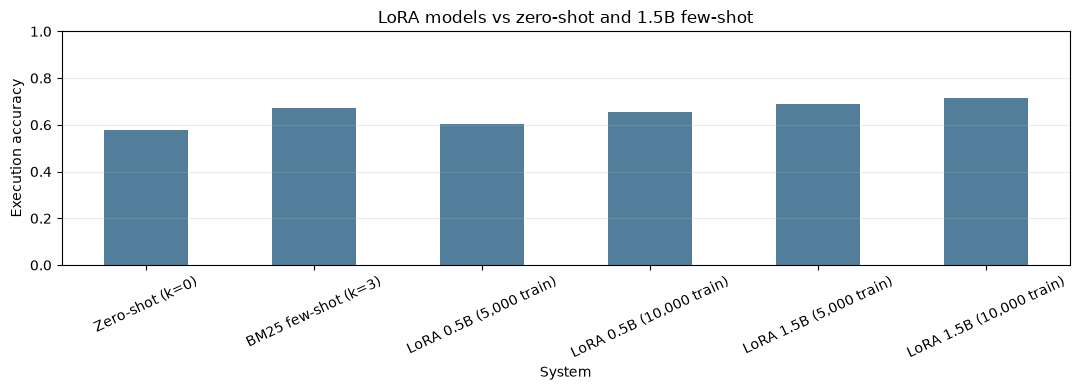

Saved: /home/aidslab/GenAI/p05-text-to-sql-analyst/results/lora_vs_fewshot.csv


In [26]:
EVAL_FULL_MODEL_ROWS = []
for system_name in ("Zero-shot (k=0)", "BM25 few-shot (k=3)"):
    records_by_id = EVAL_ARTIFACTS[system_name]
    scored = []
    for example_id in sorted(EVAL_TEST_IDS):
        record = records_by_id[example_id]
        example = EVAL_ROWS_BY_ID[example_id]
        prediction = record.get("pred", "") or ""
        predicted_rows, predicted_error = _eval_run_sql(example_id, prediction)
        gold_rows, gold_error = _eval_run_sql(example_id, example["sql"])
        scored.append({
            "correct": bool(gold_error is None and data.same_result(predicted_rows, gold_rows)),
            "exact_match": _eval_normalize_sql(prediction) == _eval_normalize_sql(example["sql"]),
            "valid_sql": predicted_error is None,
        })
    scored_df = pd.DataFrame(scored)
    EVAL_FULL_MODEL_ROWS.append({
        "system": system_name,
        "model": "Qwen2.5-Coder-1.5B-Instruct",
        "train_examples": 0,
        "n": len(scored_df),
        "execution_accuracy": scored_df["correct"].mean(),
        "exact_match": scored_df["exact_match"].mean(),
        "valid_sql": scored_df["valid_sql"].mean(),
        "metric_source": "re-executed per-example predictions",
    })

_EVAL_LORA_CONFIGS = [
    ("0.5B", 5000, "0.5B_5k"),
    ("0.5B", 10000, "0.5B_10k"),
    ("1.5B", 5000, "1.5B_5k"),
    ("1.5B", 10000, "1.5B_10k"),
]
for model_size, train_size, folder_name in _EVAL_LORA_CONFIGS:
    metrics_path = EVAL_LORA / folder_name / "test_metrics.json"
    predictions_path = EVAL_LORA / folder_name / "test_predictions.json"
    if not metrics_path.exists():
        print(f"LoRA metrics unavailable: {metrics_path.relative_to(EVAL_ROOT)}")
        continue
    with metrics_path.open(encoding="utf-8") as file:
        metrics = json.load(file)
    model_row = {
        "system": f"LoRA {model_size} ({train_size:,} train)",
        "model": model_size,
        "train_examples": train_size,
        "n": int(metrics["n_eval"]),
        "execution_accuracy": float(metrics["exec_acc"]),
        "exact_match": float(metrics["exact_match"]),
        "valid_sql": float(metrics["valid_sql"]),
        "metric_source": "saved aggregate metrics",
    }
    if predictions_path.exists():
        with predictions_path.open(encoding="utf-8") as file:
            prediction_records = json.load(file)
        prediction_map = {int(record["id"]): record for record in prediction_records}
        prediction_ids = set(prediction_map)
        if prediction_ids == EVAL_TEST_IDS:
            rescored = []
            for example_id in sorted(EVAL_TEST_IDS):
                example = EVAL_ROWS_BY_ID[example_id]
                prediction = prediction_map[example_id].get("pred", "") or ""
                predicted_rows, predicted_error = _eval_run_sql(example_id, prediction)
                gold_rows, gold_error = _eval_run_sql(example_id, example["sql"])
                rescored.append({
                    "correct": bool(gold_error is None and data.same_result(predicted_rows, gold_rows)),
                    "exact_match": _eval_normalize_sql(prediction) == _eval_normalize_sql(example["sql"]),
                    "valid_sql": predicted_error is None,
                })
            rescored_df = pd.DataFrame(rescored)
            model_row.update({
                "execution_accuracy": rescored_df["correct"].mean(),
                "exact_match": rescored_df["exact_match"].mean(),
                "valid_sql": rescored_df["valid_sql"].mean(),
                "metric_source": "re-executed per-example predictions",
            })
        else:
            print(f"ID mismatch for {folder_name}: {len(prediction_ids & EVAL_TEST_IDS)} shared IDs; using saved aggregate metrics.")
    EVAL_FULL_MODEL_ROWS.append(model_row)

EVAL_MODEL_TABLE = pd.DataFrame(EVAL_FULL_MODEL_ROWS)
EVAL_MODEL_TABLE.to_csv(EVAL_RESULTS / "lora_vs_fewshot.csv", index=False)
display(EVAL_MODEL_TABLE.style.format({
    "execution_accuracy": "{:.1%}",
    "exact_match": "{:.1%}",
    "valid_sql": "{:.1%}",
}))

_fewshot_accuracy = EVAL_MODEL_TABLE.loc[
    EVAL_MODEL_TABLE["system"] == "BM25 few-shot (k=3)", "execution_accuracy"
].iloc[0]
for small_model_row in EVAL_MODEL_TABLE[
    EVAL_MODEL_TABLE["system"].str.startswith("LoRA 0.5B")
].itertuples():
    delta = small_model_row.execution_accuracy - _fewshot_accuracy
    verdict = "beats" if delta > 0 else "does not beat"
    print(f"{small_model_row.system} {verdict} 1.5B BM25 few-shot by {delta:+.1%} execution accuracy.")

model_plot = EVAL_MODEL_TABLE.set_index("system")["execution_accuracy"].plot(
    kind="bar", figsize=(11, 4), ylim=(0, 1), color="#527e9b",
)
model_plot.set_title("LoRA models vs zero-shot and 1.5B few-shot")
model_plot.set_xlabel("System")
model_plot.set_ylabel("Execution accuracy")
model_plot.tick_params(axis="x", rotation=25)
model_plot.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(EVAL_ROOT / "lora_vs_fewshot.png", dpi=140, bbox_inches="tight")
plt.show()
print(f"Saved: {EVAL_RESULTS / 'lora_vs_fewshot.csv'}")

### 5.6 Error Analysis: Ten Failure Cases

This table includes failed SQL executions and queries that executed but returned a different result set. It prioritizes failures from the full repair agent, then fills from the baselines, all within the fixed shared cohort.

In [14]:
EVAL_FAILURES = EVAL_DF.loc[~EVAL_DF["correct"]].copy()
EVAL_FAILURES["failure_type"] = np.where(
    EVAL_FAILURES["pred_error"].notna(), "SQL execution error", "Result mismatch"
)
EVAL_FAILURES["_priority"] = np.where(EVAL_FAILURES["system"] == "Agent with repair", 0, 1)
EVAL_ERROR_ANALYSIS = (
    EVAL_FAILURES.sort_values(["_priority", "system", "id"])
    .drop_duplicates(["system", "id"])
    .head(10)
    .drop(columns="_priority")
)
EVAL_ERROR_ANALYSIS = EVAL_ERROR_ANALYSIS[[
    "system", "id", "domain", "complexity", "failure_type", "pred_error",
    "question", "pred", "gold",
]]
EVAL_ERROR_ANALYSIS.to_csv(EVAL_RESULTS / "error_analysis.csv", index=False)
display(EVAL_ERROR_ANALYSIS)
print(f"Failure cases shown: {len(EVAL_ERROR_ANALYSIS)}; saved to {EVAL_RESULTS / 'error_analysis.csv'}")

,system,id,domain,complexity,failure_type,pred_error,question,pred,gold
617,Agent with repair,33,energy,basic SQL,Result mismatch,NaN,What is the average energy rating for commerci...,SELECT AVG(energy_rating) FROM energy_efficien...,"SELECT building_type, AVG(energy_rating) FROM ..."
623,Agent with repair,159,rare earth elements,basic SQL,Result mismatch,NaN,What are the top 3 countries with the most rar...,"SELECT country, SUM(production) AS total_produ...",SELECT country FROM production ORDER BY produc...
626,Agent with repair,241,restaurant operations,basic SQL,Result mismatch,NaN,Which menu item in 'Bistro Italiano' has the h...,SELECT menu_item FROM Sales WHERE restaurant_n...,"SELECT menu_item, MAX(sales) FROM Sales WHERE ..."
652,Agent with repair,1175,hospitality,single join,Result mismatch,NaN,What is the average number of eco-friendly tou...,SELECT AVG(CASE WHEN t.eco_friendly THEN 1 ELS...,SELECT AVG(t.eco_friendly) FROM tours t JOIN h...
654,Agent with repair,1315,financial services,single join,SQL execution error,SQL operational error: no such column: T1.tran...,List all the transactions made by clients livi...,"SELECT T1.transaction_id, T1.client_id, T1.tra...","SELECT transactions.id, transactions.client_id..."
667,Agent with repair,1888,wildlife conservation,single join,Result mismatch,NaN,What is the total number of animals in the 'sa...,SELECT SUM(population) FROM sanctuary_a UNION ...,SELECT SUM(s1.population + s2.population) FROM...
671,Agent with repair,2047,cultural preservation,single join,Result mismatch,NaN,What is the total number of language learners ...,"SELECT Languages.LanguageName, SUM(LanguageLea...","SELECT Languages.LanguageName, SUM(LanguageLea..."
677,Agent with repair,2113,public transportation,subqueries,SQL execution error,"SQL operational error: unrecognized token: ""^""",What is the distance between station 5 and sta...,SELECT SQRT((latitude2 - latitude1)^2 + (longi...,SELECT 3959 * acos(cos(radians(stations.latitu...
686,Agent with repair,2495,cultural preservation,single join,SQL execution error,SQL operational error: no such column: mf.country,What is the maximum number of years a traditio...,"SELECT p.name, MAX(mf.year_preserved) FROM pro...","SELECT p.name, MAX(mf.year_preserved) FROM pro..."
692,Agent with repair,2740,fitness industry,subqueries,Result mismatch,NaN,How many users have a heart rate over 120 BPM ...,SELECT COUNT(*) FROM WorkoutData WHERE AvgHear...,"SELECT COUNT(*) FROM (SELECT UserID, SUM(Durat..."


Failure cases shown: 10; saved to /home/aidslab/GenAI/p05-text-to-sql-analyst/results/error_analysis.csv


### 5.7 Required Ablation and Deliverable Audit

This audit separates completed measurements from experiments that cannot be reconstructed from the current saved files. In particular, different retrieval methods at k=3 and k=5 are not a controlled k-only comparison, and aggregate LoRA metrics do not support domain or paired significance analyses.

In [32]:
_full_round_path = EVAL_RESULTS / "full_agent_round_ablation.csv"
_controlled_k_path = EVAL_RESULTS / "controlled_bm25_k_ablation.csv"
_lora_1k_path = EVAL_RESULTS / "lora_0.5b_1k_metrics.json"
_lora_repair_path = EVAL_RESULTS / "lora_repair_rounds.csv"
_error_analysis_path = EVAL_RESULTS / "error_analysis.csv"

if _full_round_path.exists():
    _full_round_table = pd.read_csv(_full_round_path)
    _round1_n = int(_full_round_table.loc[_full_round_table["round_limit"] == 1, "n"].iloc[0])
    _round_status = f"Complete: n={_full_round_table['n'].min()} per limit; 0/1/3 rounds"
else:
    _round1_n = int(EVAL_REPAIR_TABLE.loc[EVAL_REPAIR_TABLE["round_limit"] == 1, "n"].iloc[0])
    _round_status = f"Partial saved traces: round 1 n={_round1_n}; full-cohort rerun not found"

if _controlled_k_path.exists():
    _controlled_k_table = pd.read_csv(_controlled_k_path)
    _has_all_k = set(_controlled_k_table["k"].astype(int)) == {0, 3, 5}
    _k_status = "Complete: controlled BM25 k=0, 3, 5" if _has_all_k else "Incomplete controlled BM25 k results"
else:
    _k_status = "Not run: controlled BM25 k=0, 3, 5 results missing"

_lora_5k_path = EVAL_LORA / "0.5B_5k" / "test_metrics.json"
_lora_size_status = (
    "Complete: 1k and 5k 0.5B metrics present"
    if _lora_1k_path.exists() and _lora_5k_path.exists()
    else "Incomplete: one or more requested 0.5B training-size metrics missing"
)
_lora_repair_status = "Complete: 1k/5k repair results present" if _lora_repair_path.exists() else "Not run: LoRA repair results missing"
_error_case_count = len(pd.read_csv(_error_analysis_path)) if _error_analysis_path.exists() else 0

EVAL_ABLATION_AUDIT = pd.DataFrame([
    {"requirement": "Baseline vs full repair system", "status": f"Complete on {len(EVAL_COMMON_IDS)} shared fixed-test IDs"},
    {"requirement": "Execution accuracy by complexity and domain", "status": "Complete; tables and charts saved"},
    {"requirement": "At least 10 failure cases", "status": f"Complete; {_error_case_count} cases saved" if _error_case_count >= 10 else f"Incomplete; {_error_case_count} cases saved"},
    {"requirement": "Repair rounds {0, 1, 3}", "status": _round_status},
    {"requirement": "Retrieved examples k={0, 3, 5}", "status": _k_status},
    {"requirement": "LoRA training size {1k, 5k}", "status": _lora_size_status},
    {"requirement": "LoRA model with repair loop", "status": _lora_repair_status},
])
EVAL_ABLATION_AUDIT.to_csv(EVAL_RESULTS / "ablation_coverage.csv", index=False)
display(EVAL_ABLATION_AUDIT)

if _controlled_k_path.exists():
    EVAL_K_TABLE = _controlled_k_table[["k", "n", "execution_accuracy", "exact_match", "valid_sql"]].copy()
    EVAL_K_TABLE["retriever"] = "BM25"
    EVAL_K_TABLE = EVAL_K_TABLE[["k", "retriever", "n", "execution_accuracy", "exact_match", "valid_sql"]].sort_values("k")
else:
    EVAL_K_TABLE = EVAL_SYSTEM_TABLE[
        EVAL_SYSTEM_TABLE["system"].isin([
            "Zero-shot (k=0)", "BM25 few-shot (k=3)", "Dense few-shot (k=5)"
        ])
    ].copy()
    EVAL_K_TABLE["k"] = EVAL_K_TABLE["system"].map({
        "Zero-shot (k=0)": 0,
        "BM25 few-shot (k=3)": 3,
        "Dense few-shot (k=5)": 5,
    })
    EVAL_K_TABLE["retriever"] = EVAL_K_TABLE["system"].map({
        "Zero-shot (k=0)": "none",
        "BM25 few-shot (k=3)": "BM25",
        "Dense few-shot (k=5)": "dense",
    })
    EVAL_K_TABLE = EVAL_K_TABLE[["k", "retriever", "n", "execution_accuracy", "exact_match", "valid_sql"]].sort_values("k")

EVAL_K_TABLE.to_csv(EVAL_RESULTS / "retrieval_k_results.csv", index=False)
print("Retrieved-example results on the fixed 200-ID test split:")
display(EVAL_K_TABLE.style.format({
    "execution_accuracy": "{:.1%}",
    "exact_match": "{:.1%}",
    "valid_sql": "{:.1%}",
}))

print("\nEvaluation outputs:")
for output_path in sorted(EVAL_RESULTS.glob("*.csv")):
    print(f"  {output_path.relative_to(EVAL_ROOT)}")
for output_path in sorted(EVAL_ROOT.glob("*.png")):
    print(f"  {output_path.relative_to(EVAL_ROOT)}")

,requirement,status
0,Baseline vs full repair system,Complete on 154 shared fixed-test IDs
1,Execution accuracy by complexity and domain,Complete; tables and charts saved
2,At least 10 failure cases,Complete; 10 cases saved
3,"Repair rounds {0, 1, 3}",Complete: n=200 per limit; 0/1/3 rounds
4,"Retrieved examples k={0, 3, 5}","Complete: controlled BM25 k=0, 3, 5"
5,"LoRA training size {1k, 5k}",Complete: 1k and 5k 0.5B metrics present
6,LoRA model with repair loop,Complete: 1k/5k repair results present


Retrieved-example results on the fixed 200-ID test split:


,k,retriever,n,execution_accuracy,exact_match,valid_sql
0,0,BM25,200,58.0%,29.5%,94.0%
1,3,BM25,200,67.5%,41.0%,94.5%
2,5,BM25,200,65.5%,41.0%,91.0%



Evaluation outputs:
  results/ablation_coverage.csv
  results/accuracy_by_complexity.csv
  results/accuracy_by_domain.csv
  results/controlled_bm25_k_ablation.csv
  results/error_analysis.csv
  results/fixed_cohort_results.csv
  results/full_agent_round_ablation.csv
  results/full_agent_round_by_complexity.csv
  results/full_agent_round_cases.csv
  results/lora_comparison_with_1k.csv
  results/lora_repair_cases.csv
  results/lora_repair_rounds.csv
  results/lora_vs_fewshot.csv
  results/repair_round_ablation.csv
  results/retrieval_k_results.csv
  results/val_table.csv
  accuracy_by_complexity.png
  accuracy_by_domain.png
  agent_repair_summary.png
  lora_vs_fewshot.png
  repair_round_ablation.png


### 5.8 Controlled Retrieval Example-Count Ablation

The existing k=5 file is dense retrieval, while k=3 is BM25, so those results do not isolate example count. This optional run evaluates BM25 at k=0, 3, and 5 on the exact same fixed test IDs and prompt style. Run Parts 1-4 first, then set `RUN_CONTROLLED_K_ABLATION = True`.

In [17]:
RUN_CONTROLLED_K_ABLATION = False

if RUN_CONTROLLED_K_ABLATION:
    if "run_system" not in globals() or "PROMPT_STYLE" not in globals():
        raise RuntimeError("Run Parts 1-4 first so the RAG model, BM25 index, and run_system are available.")
    if PROMPT_STYLE == "auto":
        raise RuntimeError("Finish Part 2 prompt-style selection first; PROMPT_STYLE is still 'auto'.")

    _retrieval_test_rows = [EVAL_ROWS_BY_ID[i] for i in sorted(EVAL_TEST_IDS)]
    _retrieval_rows = []
    for _k in (0, 3, 5):
        _mode = "zero" if _k == 0 else "bm25"
        _tag = f"test_controlled_bm25_k{_k}"
        _df = run_system(
            f"bm25_k{_k}", _mode, _k, _retrieval_test_rows,
            PROMPT_STYLE, tag=_tag,
        )
        _retrieval_rows.append({
            "system": f"BM25 k={_k}",
            "k": _k,
            "n": len(_df),
            "execution_accuracy": _df["correct"].mean(),
            "exact_match": _df.apply(
                lambda row: _eval_normalize_sql(row["pred"]) == _eval_normalize_sql(row["gold"]),
                axis=1,
            ).mean(),
            "valid_sql": _df["error"].isna().mean(),
            "prompt_style": PROMPT_STYLE,
        })

    CONTROLLED_K_TABLE = pd.DataFrame(_retrieval_rows)
    CONTROLLED_K_TABLE.to_csv(EVAL_RESULTS / "controlled_bm25_k_ablation.csv", index=False)
    display(CONTROLLED_K_TABLE.style.format({
        "execution_accuracy": "{:.1%}",
        "exact_match": "{:.1%}",
        "valid_sql": "{:.1%}",
    }))
else:
    print("Controlled BM25 k ablation is ready but not run. Run Parts 1-4, then set RUN_CONTROLLED_K_ABLATION = True.")

Controlled BM25 k ablation is ready but not run. Run Parts 1Ã¢â‚¬â€œ4, then set RUN_CONTROLLED_K_ABLATION = True.


### 5.9 Full-Cohort Agent Repair-Round Ablation

The saved agent traces are incomplete for some intermediate repairs. This optional rerun generates each fixed test question once with up to three repairs, scores the SQL candidate available at limits 0, 1, and 3, and reports each limit on the full cohort. Run Parts 1-4 first, then set `RUN_FULL_AGENT_ROUND_ABLATION = True`.

In [18]:
RUN_FULL_AGENT_ROUND_ABLATION = False

if RUN_FULL_AGENT_ROUND_ABLATION:
    if "agent" not in globals():
        raise RuntimeError("Run Part 3 first so the LangGraph agent and base model are available.")

    _agent_round_cases = []
    _agent_trace_records = []
    _round_prefixes = {
        0: "[Round 0 | GENERATE] SQL: ",
    }

    for _example_id in sorted(EVAL_TEST_IDS):
        _example = EVAL_ROWS_BY_ID[_example_id]
        _final_sql, _answer, _trace = agent(
            _example["sql_prompt"], _example["sql_context"], max_repairs=3
        )
        _sql_by_round = {}
        for _step in _trace:
            if _step.startswith(_round_prefixes[0]):
                _sql_by_round[0] = _step[len(_round_prefixes[0]):].strip()
            elif " | REPAIR]" in _step:
                _round_number = int(_step.split("[Round ", 1)[1].split(" |", 1)[0])
                _marker = " -> SQL: "
                if _marker in _step:
                    _sql_by_round[_round_number] = _step.split(_marker, 1)[1].strip()

        if 0 not in _sql_by_round:
            raise ValueError(f"Could not recover round-0 SQL from agent trace for test ID {_example_id}.")
        _sql_by_round[max(_sql_by_round)] = _final_sql.strip()
        _gold_rows, _gold_error = data.run_sql(_example["sql_context"], _example["sql"])
        _agent_trace_records.append({
            "id": _example_id,
            "question": _example["sql_prompt"],
            "complexity": _example["sql_complexity"],
            "round_queries": _sql_by_round,
            "rounds_generated": max(_sql_by_round),
        })

        for _limit in (0, 1, 3):
            _available_round = max((r for r in _sql_by_round if r <= _limit), default=0)
            _candidate_sql = _sql_by_round[_available_round]
            _pred_rows, _pred_error = data.run_sql(_example["sql_context"], _candidate_sql)
            _is_correct = bool(
                _gold_error is None and _pred_error is None
                and data.same_result(_pred_rows, _gold_rows)
            )
            _agent_round_cases.append({
                "id": _example_id,
                "complexity": _example["sql_complexity"],
                "round_limit": _limit,
                "candidate_round": _available_round,
                "correct": _is_correct,
                "initial_correct": bool(
                    data.same_result(
                        data.run_sql(_example["sql_context"], _sql_by_round[0])[0],
                        _gold_rows,
                    ) if _gold_error is None else False
                ),
                "repair_rounds_used": min(_available_round, _limit),
                "error": _pred_error,
            })

    FULL_AGENT_ROUND_CASES = pd.DataFrame(_agent_round_cases)
    FULL_AGENT_ROUND_CASES.to_csv(EVAL_RESULTS / "full_agent_round_cases.csv", index=False)
    FULL_AGENT_ROUND_TABLE = (
        FULL_AGENT_ROUND_CASES.groupby("round_limit")
        .agg(
            n=("id", "nunique"),
            execution_accuracy=("correct", "mean"),
            avg_rounds_used=("repair_rounds_used", "mean"),
        )
        .reset_index()
    )
    for _row_index, _row in FULL_AGENT_ROUND_TABLE.iterrows():
        _cases_at_limit = FULL_AGENT_ROUND_CASES[
            FULL_AGENT_ROUND_CASES["round_limit"] == int(_row["round_limit"])
        ]
        _initial_failures = int((~_cases_at_limit["initial_correct"]).sum())
        _repaired_count = int((~_cases_at_limit["initial_correct"] & _cases_at_limit["correct"]).sum())
        FULL_AGENT_ROUND_TABLE.loc[_row_index, "repair_success_rate"] = (
            _repaired_count / _initial_failures if _initial_failures else np.nan
        )
    FULL_AGENT_ROUND_TABLE.to_csv(EVAL_RESULTS / "full_agent_round_ablation.csv", index=False)

    FULL_AGENT_BY_COMPLEXITY = (
        FULL_AGENT_ROUND_CASES.groupby(["round_limit", "complexity"])
        .agg(n=("id", "nunique"), execution_accuracy=("correct", "mean"))
        .reset_index()
    )
    FULL_AGENT_BY_COMPLEXITY.to_csv(EVAL_RESULTS / "full_agent_round_by_complexity.csv", index=False)
    display(FULL_AGENT_ROUND_TABLE.style.format({
        "execution_accuracy": "{:.1%}",
        "repair_success_rate": "{:.1%}",
        "avg_rounds_used": "{:.2f}",
    }))
    print(f"Full-cohort agent repair results saved for {len(EVAL_TEST_IDS)} IDs.")
else:
    print("Full-cohort repair-round rerun is ready but not run. Run Parts 1-4, then set RUN_FULL_AGENT_ROUND_ABLATION = True.")

Full-cohort repair-round rerun is ready but not run. Run Parts 1Ã¢â‚¬â€œ4, then set RUN_FULL_AGENT_ROUND_ABLATION = True.


### 5.10 Missing 1k LoRA and LoRA-with-Repair Evaluations

The 1k run trains the existing 0.5B LoRA pipeline on 1,000 clean training examples and evaluates it on the fixed 200-ID test split. The repair evaluation feeds each execution error or empty result back into the same LoRA model, up to three rounds. These runs require a CUDA GPU and are opt-in; existing adapters and results are never overwritten.

In [19]:
RUN_LORA_1K_TRAINING = False
RUN_LORA_REPAIR_EVALS = False
LORA_1K_ADAPTER = EVAL_ROOT / "notebook_adapters" / "lora_0.5b_1k"
LORA_1K_METRICS = EVAL_RESULTS / "lora_0.5b_1k_metrics.json"
LORA_1K_PREDICTIONS = EVAL_RESULTS / "lora_0.5b_1k_predictions.json"

if RUN_LORA_1K_TRAINING:
    _part4_functions = ("train_lora", "eval_lora_detailed", "CONFIG")
    _missing_part4_functions = [name for name in _part4_functions if name not in globals()]
    if _missing_part4_functions:
        raise RuntimeError(f"Run the Part 4 model-definition cell first: missing {_missing_part4_functions}")
    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("LoRA training requires a CUDA GPU; no CUDA device is available in this kernel.")
    if LORA_1K_ADAPTER.exists():
        raise FileExistsError(f"Refusing to overwrite the existing adapter directory: {LORA_1K_ADAPTER}")

    _train_ds, _, _test_ds = data.get_splits(quick_run=False)
    train_lora(
        _train_ds,
        n=1000,
        epochs=1,
        r=16,
        lr=2e-4,
        adapter=str(LORA_1K_ADAPTER),
        batch_size=2,
        grad_accum=8,
        grad_ckpt=True,
        log_file=EVAL_RESULTS / "lora_0.5b_1k_training.log",
        base=CONFIG["lora_base"],
        dtype=torch.float32,
        max_len=512,
    )
    _lora_1k_metrics = eval_lora_detailed(
        _test_ds,
        adapter=str(LORA_1K_ADAPTER),
        name="LoRA 0.5B (1,000 examples)",
        base=CONFIG["lora_base"],
        out_txt=EVAL_RESULTS / "lora_0.5b_1k_test.log",
        out_json=LORA_1K_PREDICTIONS,
    )
    LORA_1K_METRICS.write_text(json.dumps(_lora_1k_metrics, indent=2), encoding="utf-8")
    print(f"Saved 1k LoRA metrics to {LORA_1K_METRICS}")
else:
    print("1k LoRA training/evaluation is ready but not run. Set RUN_LORA_1K_TRAINING = True to train on CUDA.")


if RUN_LORA_REPAIR_EVALS:
    _part4_repair_functions = ("generate_lora", "_load")
    _missing_repair_functions = [name for name in _part4_repair_functions if name not in globals()]
    if _missing_repair_functions:
        raise RuntimeError(f"Run the Part 4 model-definition cell first: missing {_missing_repair_functions}")
    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("LoRA repair evaluation requires CUDA because the existing Part 4 loader places models on CUDA.")

    _lora_repair_adapters = [
        ("LoRA 0.5B (5k) + repair", EVAL_LORA / "0.5B_5k" / "adapter"),
        ("LoRA 0.5B (1k) + repair", LORA_1K_ADAPTER),
    ]
    _repair_case_rows = []
    for _adapter_name, _adapter_path in _lora_repair_adapters:
        if not (_adapter_path / "adapter_config.json").exists():
            print(f"Skipping {_adapter_name}; adapter not found at {_adapter_path}")
            continue
        for _example_id in sorted(EVAL_TEST_IDS):
            _example = EVAL_ROWS_BY_ID[_example_id]
            _gold_rows, _gold_error = data.run_sql(_example["sql_context"], _example["sql"])
            _sql_by_round = {}
            _candidate_sql = generate_lora(
                _example["sql_prompt"], _example["sql_context"],
                adapter=str(_adapter_path), max_new_tokens=256, stop=(";",), clean=True,
            )
            for _round_number in range(4):
                _sql_by_round[_round_number] = _candidate_sql
                _pred_rows, _pred_error = data.run_sql(_example["sql_context"], _candidate_sql)
                if _pred_error is None and _pred_rows:
                    break
                if _round_number == 3:
                    break
                _feedback = _pred_error or "The query executed but returned an empty result set."
                _repair_question = (
                    f"{_example['sql_prompt']}\n\n"
                    f"Previous SQL: {_candidate_sql}\n"
                    f"Execution feedback: {_feedback}\n"
                    "Correct the SQL using only the supplied schema. Return one SQLite SELECT query."
                )
                _candidate_sql = generate_lora(
                    _repair_question, _example["sql_context"],
                    adapter=str(_adapter_path), max_new_tokens=256, stop=(";",), clean=True,
                )

            for _limit in (0, 1, 3):
                _candidate_round = min(_limit, max(_sql_by_round))
                _sql = _sql_by_round[_candidate_round]
                _pred_rows, _pred_error = data.run_sql(_example["sql_context"], _sql)
                _is_correct = bool(
                    _gold_error is None and _pred_error is None
                    and data.same_result(_pred_rows, _gold_rows)
                )
                _initial_sql = _sql_by_round[0]
                _initial_rows, _initial_error = data.run_sql(_example["sql_context"], _initial_sql)
                _initial_correct = bool(
                    _gold_error is None and _initial_error is None
                    and data.same_result(_initial_rows, _gold_rows)
                )
                _repair_case_rows.append({
                    "system": _adapter_name,
                    "id": _example_id,
                    "complexity": _example["sql_complexity"],
                    "round_limit": _limit,
                    "candidate_round": _candidate_round,
                    "correct": _is_correct,
                    "exact_match": _eval_normalize_sql(_sql) == _eval_normalize_sql(_example["sql"]),
                    "initial_correct": _initial_correct,
                    "repair_success": (not _initial_correct and _is_correct),
                    "repair_rounds_used": _candidate_round,
                    "pred": _sql,
                    "gold": _example["sql"],
                    "error": _pred_error,
                })

    if _repair_case_rows:
        LORA_REPAIR_CASES = pd.DataFrame(_repair_case_rows)
        LORA_REPAIR_CASES.to_csv(EVAL_RESULTS / "lora_repair_cases.csv", index=False)
        LORA_REPAIR_TABLE = (
            LORA_REPAIR_CASES.groupby(["system", "round_limit"])
            .agg(
                n=("id", "nunique"),
                execution_accuracy=("correct", "mean"),
                exact_match=("exact_match", "mean"),
                avg_rounds_used=("repair_rounds_used", "mean"),
                repair_success_rate=("repair_success", lambda values: values.sum() / max(
                    int((~LORA_REPAIR_CASES.loc[values.index, "initial_correct"]).sum()), 1
                )),
            )
            .reset_index()
        )
        LORA_REPAIR_TABLE.to_csv(EVAL_RESULTS / "lora_repair_rounds.csv", index=False)
        display(LORA_REPAIR_TABLE.style.format({
            "execution_accuracy": "{:.1%}",
            "exact_match": "{:.1%}",
            "repair_success_rate": "{:.1%}",
            "avg_rounds_used": "{:.2f}",
        }))
        print(f"Saved LoRA repair metrics to {EVAL_RESULTS / 'lora_repair_rounds.csv'}")
else:
    print("LoRA-plus-repair evaluation is ready but not run. Set RUN_LORA_REPAIR_EVALS = True after Part 4 and confirm the adapters are present.")

1k LoRA training/evaluation is ready but not run. Set RUN_LORA_1K_TRAINING = True to train on CUDA.
LoRA-plus-repair evaluation is ready but not run. Set RUN_LORA_REPAIR_EVALS = True after Part 4 and confirm the adapters are present.


### 5.11 Missing-Run Status

The optional runs above are intentionally disabled by default because they require the Parts 1-4 model/index setup and GPU inference or training. This table reflects whether their result artifacts have actually been produced.

In [30]:
_missing_run_checks = [
    ("Controlled BM25 k={0, 3, 5}", EVAL_RESULTS / "controlled_bm25_k_ablation.csv", "Run Parts 1-4, then enable RUN_CONTROLLED_K_ABLATION."),
    ("Full-cohort agent rounds {0, 1, 3}", EVAL_RESULTS / "full_agent_round_ablation.csv", "Run Parts 1-4, then enable RUN_FULL_AGENT_ROUND_ABLATION."),
    ("0.5B LoRA 1k direct evaluation", LORA_1K_METRICS, "Enable RUN_LORA_1K_TRAINING on a CUDA runtime."),
    ("0.5B LoRA plus repair", EVAL_RESULTS / "lora_repair_rounds.csv", "Enable RUN_LORA_REPAIR_EVALS after Part 4 and confirm adapters exist."),
]
MISSING_RUN_STATUS = pd.DataFrame([
    {
        "evaluation": name,
        "status": "Complete" if output_path.exists() else "Not run",
        "result_file": str(output_path.relative_to(EVAL_ROOT)),
        "next_step": "" if output_path.exists() else instruction,
    }
    for name, output_path, instruction in _missing_run_checks
])
display(MISSING_RUN_STATUS)

if LORA_1K_METRICS.exists():
    with LORA_1K_METRICS.open(encoding="utf-8") as file:
        _one_k_metrics = json.load(file)
    _one_k_row = pd.DataFrame([{
        "system": "LoRA 0.5B (1,000 train)",
        "model": "0.5B",
        "train_examples": 1000,
        "n": int(_one_k_metrics["n_eval"]),
        "execution_accuracy": float(_one_k_metrics["exec_acc"]),
        "exact_match": float(_one_k_metrics["exact_match"]),
        "valid_sql": float(_one_k_metrics["valid_sql"]),
        "metric_source": "saved aggregate metrics",
    }])
    COMPLETED_MODEL_TABLE = pd.concat([EVAL_MODEL_TABLE, _one_k_row], ignore_index=True)
    COMPLETED_MODEL_TABLE.to_csv(EVAL_RESULTS / "lora_comparison_with_1k.csv", index=False)
    print(f"Updated LoRA comparison saved to {EVAL_RESULTS / 'lora_comparison_with_1k.csv'}")

,evaluation,status,result_file,next_step
0,"Controlled BM25 k={0, 3, 5}",Complete,results/controlled_bm25_k_ablation.csv,
1,"Full-cohort agent rounds {0, 1, 3}",Complete,results/full_agent_round_ablation.csv,
2,0.5B LoRA 1k direct evaluation,Complete,results/lora_0.5b_1k_metrics.json,
3,0.5B LoRA plus repair,Complete,results/lora_repair_rounds.csv,


Updated LoRA comparison saved to /home/aidslab/GenAI/p05-text-to-sql-analyst/results/lora_comparison_with_1k.csv


## 6. Demo

Run the complete Part 3 agent on one fixed test example after the preceding setup, retrieval, and model cells have been executed. The demo prints the generated SQL, final answer, and repair trace.

In [ ]:
# Demo: one end-to-end question through the agent and repair loop.
if 'agent' not in globals():
    raise RuntimeError('Run the Part 3 agent cells before running this demo cell.')

_demo_examples = list(test_eval) if 'test_eval' in globals() else []
if not _demo_examples:
    raise RuntimeError('Run the data and split cells before running this demo cell.')

_demo = _demo_examples[0]
_demo_sql, _demo_answer, _demo_trace = agent(_demo['sql_prompt'], _demo['sql_context'])
print('Question:', _demo['sql_prompt'])
print('Generated SQL:', _demo_sql)
print('Answer:', _demo_answer)
print('Trace:')
for _step in _demo_trace:
    print(' ', _step)

## 7. Limitations & Ethics

- The synthetic dataset contains SQL that is not always SQLite-compatible; execution failures are separated from model failures where possible.
- The read-only SQLite harness blocks writes and DDL, so the system is intended for analysis rather than database mutation.
- Generated SQL can return plausible but incorrect answers, especially for joins, aggregation, ambiguous questions, and unseen schemas.
- Fine-tuning and large-model evaluation may require substantial memory, download time, and a CUDA-capable GPU.
- Do not use the system for high-stakes decisions without human review, query inspection, and independent validation.

## 8. References

- Dataset: `gretelai/synthetic_text_to_sql`.
- Base models: Qwen2.5 instruct/coder checkpoints and `sentence-transformers/all-MiniLM-L6-v2`.
- Retrieval: FAISS, BM25, reciprocal-rank fusion, masked-question retrieval, and skeleton retrieval.
- Agent framework: LangGraph with an execution-guided repair loop.
- Fine-tuning: PEFT LoRA and the saved adapters under `lora_experiment_results/` and `notebook_adapters/`.
- Project modules: `config.py`, `data.py`, fixed split ID files, and the result artifacts under `results/`.
- Course material reused: RAG pipeline, structured generation, tool calling, and reflexion/self-repair patterns.